# "The Entrainment of Air from Rainy Surface Regions and its Implications for Bioaerosol Transport in Three Deep Convective Storm Morphologies" (Davis et al.) analysis notebook

This notebook produces all of the analysis and figures presented in the manuscript named above. Assuming the required RAMS output is present, it should work out of the box (or nearly so),
with only a few possible changes you could need to make, described here:

* The `common` and `blt_utils` packages used throughout are included, and should be found automatically by python. If they are not,
  you can ensure that the appropriate directories/locations are included using `sys.path.append`.
* Assuming you have reproduced the RAMS output, you will need to modify the `RAMS_OUTPUT_DIRS` variable in `blt_utils.py` to point to the
  directories containing the RAMS output for each storm. All other paths are relative and should not need to be adjusted.
* If `USE_DASK_LOCAL_CLUSTER` is set to True, xarray will try to read in the RAMS data using the dask backend. This is set to False
  by default so that the code will work, but if you wish to use dask, start your own scheduler and modify the `DASK_SCHEDULER_ADDRESS`
  variable in `blt_utils.py`
* In the "Read/calculate data"/"Tracer concentration files" and "Read/calculate data"/"Development dataframes" cells below,
  the flags for each storm in the top of the cell can be set to False to recalculate the derived dataset from the raw
  RAMS output. With the default True, these will be read from disk (they are included with the repo).

# Setup

## Imports

In [1]:
# Native packages
from pathlib import Path
from importlib import reload
import re

# Other packages
import pandas as pd
import xarray as xr
import pint_xarray
import numpy as np
from metpy.plots import SkewT, Hodograph
import metpy.calc as mpc
from metpy.units import units
import metpy.constants as mpconstants
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.pyplot as plt
import matplotlib.animation as mplanim
from matplotlib.animation import FuncAnimation
from matplotlib import cm, ticker
import matplotlib.colors as colors
import matplotlib as mpl
import matplotlib.patches as patches
from IPython.display import HTML, display, Image
from tqdm.notebook import tqdm
import pickle as pkl
from scipy import interpolate

# My packages
import common as cm
import blt_utils as blt

plt.style.use(blt.MPL_STYLE)

## Parameters

In [2]:
# Explicitly parallelizing over the local machine is similaraly finnicky, so add a flag for it
USE_DASK_LOCAL_CLUSTER = True

display(blt.RAMS_OUTPUT_DIRS)
display(blt.DEVELOPMENT_DATAFRAME_FILEPATHS)
display(blt.TRACER_TOTALS_PROFILE_FILEPATHS)

{'ic_wk': PosixPath('/moonbow/cmdavis4/projects/bl_transport/rams_io/isolated_convection_wk/all_tracers/newtracer_forcing-warmbubble4_deltax-500_frqlite-2_nobulku/output'),
 'sl_wk': PosixPath('/moonbow/cmdavis4/projects/bl_transport/rams_io/squall_line_wk/all_tracers/newtracer_blspinup-no_forcing-infinitecoldbubble4_deltax-500_frqlite-2/output'),
 'sc_wk': PosixPath('/moonbow/cmdavis4/projects/bl_transport/rams_io/supercell_wk/all_tracers/newtracer_forcing-grant2014_dx-500_frqlite-2_stratwinds/output')}

{'ic_wk': PosixPath('/home/cmdavis4/projects/tracer_paper/data/derived/ic_wk/development_dataframe.pkl'),
 'sl_wk': PosixPath('/home/cmdavis4/projects/tracer_paper/data/derived/sl_wk/development_dataframe.pkl'),
 'sc_wk': PosixPath('/home/cmdavis4/projects/tracer_paper/data/derived/sc_wk/development_dataframe.pkl')}

{'ic_wk': PosixPath('/home/cmdavis4/projects/tracer_paper/data/derived/ic_wk/tracer_totals_profile_ds.nc'),
 'sl_wk': PosixPath('/home/cmdavis4/projects/tracer_paper/data/derived/sl_wk/tracer_totals_profile_ds.nc'),
 'sc_wk': PosixPath('/home/cmdavis4/projects/tracer_paper/data/derived/sc_wk/tracer_totals_profile_ds.nc')}

## Dask cluster

In [3]:
if USE_DASK_LOCAL_CLUSTER:
    from dask.distributed import Client

    # The default scheduler port is 8786, but can change this if need be
    client = Client(blt.DASK_SCHEDULER_ADDRESS)

# Read/calculate data

## 5 minute RAMS output

In [4]:
reload(cm.rams)
reload(blt)

# Define the list of RAMS output filenames we'll read in
# Can specify this manually or just use a glob
rams_input_filename_glob = "a-A-*.h5"

rams_input_dim_names_kwargs = (
    {
        "dim_names": {
            "phony_dim_0": "y",
            "phony_dim_1": "x",
            "phony_dim_2": "p",
            "phony_dim_3": "z",
        }
    }
    if rams_input_filename_glob.startswith("a-L")
    else {}
)

storm_dss = {}

for storm_name in tqdm(list(blt.STORM_LABELS.keys())):
    rams_input_filenames = sorted(
        list(blt.RAMS_OUTPUT_DIRS[storm_name].glob(rams_input_filename_glob))
    )

    # Read in the RAMS output
    storm_ds = cm.rams.read_rams_output(
        input_filenames=rams_input_filenames,
        time_dim_name="time",
        units=False,
        **rams_input_dim_names_kwargs,
    )

    # Postprocess
    storm_ds = blt.postprocess_storm_ds(storm_ds, storm_name)

    # Store
    storm_dss[storm_name] = storm_ds


# Calculate the timestep and horizontal grid spacing, assuming they are uniform
# Doesn't matter which storm ds we use
DELTA_T = (storm_ds["time"].values[1] - storm_ds["time"].values[0]) / np.timedelta64(
    1, "s"
)
DELTA_X = storm_ds["x"].values[1] - storm_ds["x"].values[0]

  0%|          | 0/3 [00:00<?, ?it/s]

Reading and concatenating 37 RAMS individual timestep outputs...
Reading and concatenating 37 RAMS individual timestep outputs...
Reading and concatenating 37 RAMS individual timestep outputs...


## Tracer concentration files

In [5]:
reload(blt)

# Whether to read this from disk; if not, it recalculates it and save it to disk
READ_TRACER_CONCENTRATIONS = {"ic_wk": True, "sl_wk": True, "sc_wk": True}

tracer_totals_profile_dss = {}
for storm, storm_ds in storm_dss.items():

    tracer_totals_profile_filepath = blt.TRACER_TOTALS_PROFILE_FILEPATHS[storm]
    print(tracer_totals_profile_filepath)
    # continue
    if READ_TRACER_CONCENTRATIONS[storm]:
        tracer_totals_profile_ds = xr.open_dataset(tracer_totals_profile_filepath)
    else:
        tracer_totals_profile_ds = blt.calculate_tracer_profile_ds(
            storm_ds.where(storm_ds["in_analysis"])
        )
        # Save it to disk
        print("Saving...")
        tracer_totals_profile_ds.to_netcdf(tracer_totals_profile_filepath)
    # Store it
    tracer_totals_profile_dss[storm] = tracer_totals_profile_ds

# Calculate totals across vertical levels
tracer_totals_dss = {
    k: v.isel({"z": slice(1, len(v["z"]))}).sum("z")
    for k, v in tracer_totals_profile_dss.items()
}

/home/cmdavis4/projects/tracer_paper/data/derived/ic_wk/tracer_totals_profile_ds.nc
/home/cmdavis4/projects/tracer_paper/data/derived/sl_wk/tracer_totals_profile_ds.nc
/home/cmdavis4/projects/tracer_paper/data/derived/sc_wk/tracer_totals_profile_ds.nc


## Development dataframes

In [6]:
reload(blt)

READ_DEVELOPMENT_DATAFRAMES = {"ic_wk": True, "sl_wk": True, "sc_wk": True}

development_dfs = {}

for storm, storm_ds in tqdm(storm_dss.items()):

    development_df_filepath = blt.DEVELOPMENT_DATAFRAME_FILEPATHS[storm]
    print(development_df_filepath)

    if READ_DEVELOPMENT_DATAFRAMES[storm]:
        development_df = pd.read_pickle(development_df_filepath)
    else:
        development_df = blt.calculate_development_dataframe(
            storm_ds.where(storm_ds["in_analysis"])
        )
        # Write it to disk
        development_df.to_pickle(development_df_filepath)

    # Store it
    development_dfs[storm] = development_df

    # Attach the storm positions to the storm datasets
    for coord in ["x", "y"]:
        storm_dss[storm][f"storm_position_{coord}"] = xr.DataArray(
            development_df[f"storm_centroid_{coord}"].values,
            coords={
                "time": [
                    blt.minutes_to_simulation_time(x)
                    for x in development_df["t_minutes"].values
                ]
            },
        )

  0%|          | 0/3 [00:00<?, ?it/s]

/home/cmdavis4/projects/tracer_paper/data/derived/ic_wk/development_dataframe.pkl
/home/cmdavis4/projects/tracer_paper/data/derived/sl_wk/development_dataframe.pkl
/home/cmdavis4/projects/tracer_paper/data/derived/sc_wk/development_dataframe.pkl


In [7]:
development_dfs["ic_wk"]

,t_minutes,max_updraft,updraft_mass,total_rain,storm_centroid_x,storm_centroid_y,rain_threshold0,rain_threshold1,rain_threshold2,rain_threshold3,rain_threshold4
0,0.0,NaN,0.000000e+00,0.000000,NaN,NaN,0,0,0,0,0
1,5.0,NaN,0.000000e+00,0.000000,NaN,NaN,0,0,0,0,0
2,10.0,0.023983,0.000000e+00,0.000000,NaN,NaN,0,0,0,0,0
3,15.0,0.030488,0.000000e+00,0.000000,NaN,NaN,0,0,0,0,0
4,20.0,0.024406,0.000000e+00,0.000000,NaN,NaN,0,0,0,0,0
5,25.0,0.019785,0.000000e+00,0.000000,NaN,NaN,0,0,0,0,0
6,30.0,0.019648,0.000000e+00,0.000000,NaN,NaN,0,0,0,0,0
7,35.0,0.021760,0.000000e+00,0.000000,NaN,NaN,0,0,0,0,0
8,40.0,0.078784,3.278576e+10,0.000000,NaN,NaN,0,0,0,0,0
9,45.0,0.466450,1.144786e+11,0.000000,NaN,NaN,0,0,0,0,0


In [8]:
development_dfs["sc_wk"]

,t_minutes,max_updraft,updraft_mass,total_rain,storm_centroid_x,storm_centroid_y,rain_threshold0,rain_threshold1,rain_threshold2,rain_threshold3,rain_threshold4
0,0.0,NaN,0.000000e+00,0.000000,NaN,NaN,0,0,0,0,0
1,5.0,NaN,0.000000e+00,0.000000,NaN,NaN,0,0,0,0,0
2,10.0,0.228397,1.196704e+10,0.000000,NaN,NaN,0,0,0,0,0
3,15.0,0.388319,2.553478e+10,0.000000,NaN,NaN,0,0,0,0,0
4,20.0,0.579281,3.938419e+10,0.000006,NaN,NaN,0,0,0,0,0
5,25.0,1.172175,6.093900e+10,0.000013,NaN,NaN,0,0,0,0,0
6,30.0,2.052900,1.002089e+11,0.000039,82750.000000,75750.000000,0,0,0,0,0
7,35.0,3.947074,1.616796e+11,0.002625,83621.212121,78696.969697,0,0,0,0,0
8,40.0,8.112572,2.507986e+11,0.175063,87313.333333,81233.333333,207,0,0,0,0
9,45.0,13.761439,4.034963e+11,0.653657,92309.090909,83472.727273,464,198,14,0,0


# Paper figures

## Storm soundings

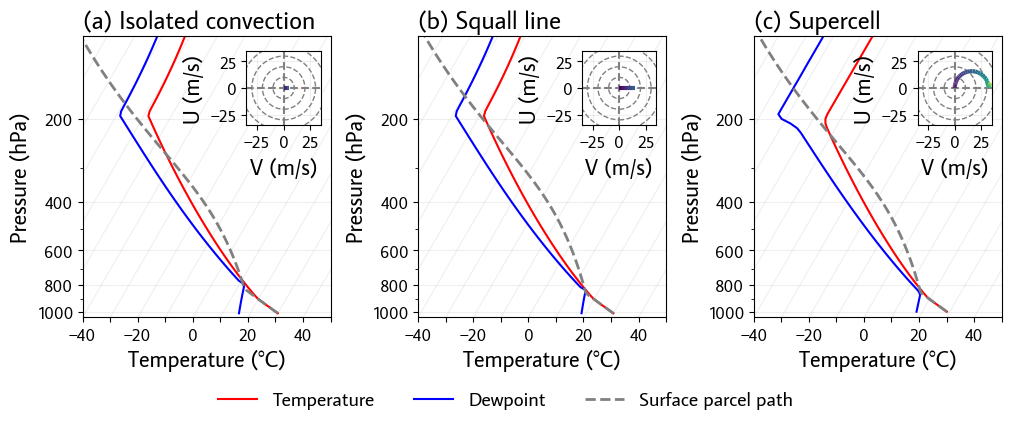

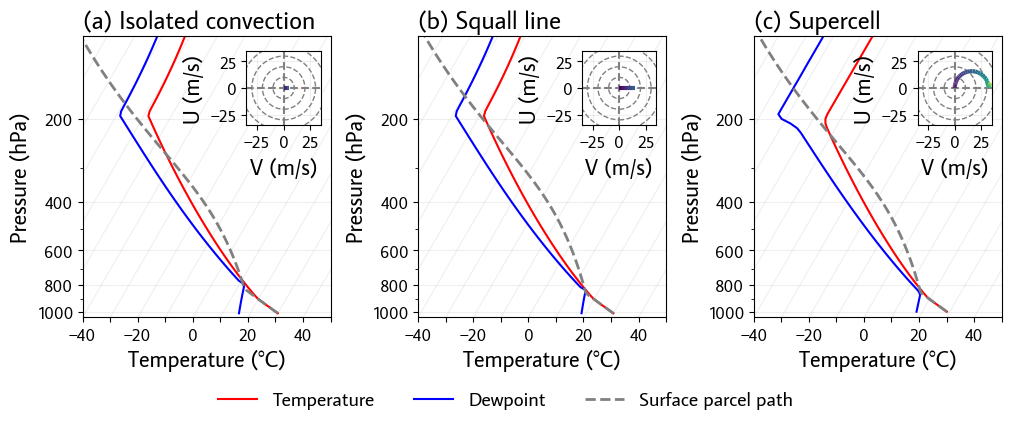

In [9]:
reload(blt)

figure_name = "f01_skewt_logp"
figure_data = {}

storm_skewt_dfs = {
    storm: storm_ds.isel({"time": 0})
    .mean(["x", "y"])[["P", "T", "dewpoint", "UC", "VC"]]
    .to_pandas()
    .reset_index()
    for storm, storm_ds in storm_dss.items()
}

import matplotlib.ticker as ticker

fig = plt.figure(figsize=(10, 5), layout="constrained")
subfigs = fig.subfigures(ncols=3)


def convert_np(arr, ufrom, uto):
    return (arr * units(ufrom)).to(uto).magnitude


legend_artists = []

for storm_ix, (storm, storm_ds) in enumerate(storm_skewt_dfs.items()):

    subfig = subfigs[storm_ix]
    wk_skewt = SkewT(subfig, rotation=30, aspect=1 * 100)
    t_line = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_skewt_temperature",
        wk_skewt.plot,
        storm_ds["P"].values,
        convert_np(storm_ds["T"].values, "K", "degC"),
        "r",
        label="Temperature",
    )
    dp_line = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_skewt_dewpoint",
        wk_skewt.plot,
        storm_ds["P"].values,
        convert_np(storm_ds["dewpoint"].values, "K", "degC"),
        "blue",
        label="Dewpoint",
    )

    # Calculate and plot parcel profile
    wk_parcel_path = mpc.parcel_profile(
        storm_ds["P"].values * units("hPa"),
        storm_ds["T"].values[0] * units("K"),
        storm_ds["dewpoint"].values[0] * units("K"),
    )
    parcel_line = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_surface_parcel_path",
        wk_skewt.plot,
        storm_ds["P"].values,
        wk_parcel_path,
        color="grey",
        linestyle="dashed",
        linewidth=2,
        label="Surface parcel path",
    )
    # subfig.suptitle(f"$U_S$={Us} m/s, $Q_{{v0}}$={qv0} g/kg, shear scale height={zscale} m")

    # Add a hodograph
    from mpl_toolkits.axes_grid1.inset_locator import inset_axes

    skewt_ax = wk_skewt.ax
    skewt_ax.set_xlabel("Temperature (°C)")
    skewt_ax.set_ylabel("Pressure (hPa)")
    skewt_ax.yaxis.set_major_locator(ticker.MultipleLocator(200))
    for label in skewt_ax.xaxis.get_ticklabels()[1::2]:
        label.set_visible(False)

    ax_hod = inset_axes(skewt_ax, "30%", "30%", loc=1)
    h = Hodograph(ax_hod, component_range=35.0)
    h.add_grid(increment=10)
    # Only add the winds up to 4 km, so we can see the variation in hodograph color
    this_hodo_ds = storm_ds.loc[storm_ds["z"] <= 8000]
    blt.plot_and_save(
        figure_data,
        f"storm-{storm}_hogograph",
        h.plot_colormapped,
        this_hodo_ds["UC"].values,
        this_hodo_ds["VC"].values,
        this_hodo_ds["z"].values,
    )
    ax_hod.set_ylabel("U (m/s)")
    ax_hod.set_xlabel("V (m/s)")

    skewt_ax.set_title(blt.axes_title(storm_ix, blt.STORM_LABELS[storm]))
    # Save the legend artists; this just gets overwritten every time, which is fine
    legend_artists[:] = [t_line[0], dp_line[0], parcel_line[0]]

fig.legend(handles=legend_artists, loc="lower center", ncols=3)

blt.save_figure_data(figure_data, figure_name)
cm.plotting.fig_multisave(fig, figure_name, blt.FIGS_DIR)

## Tracer emission schematic

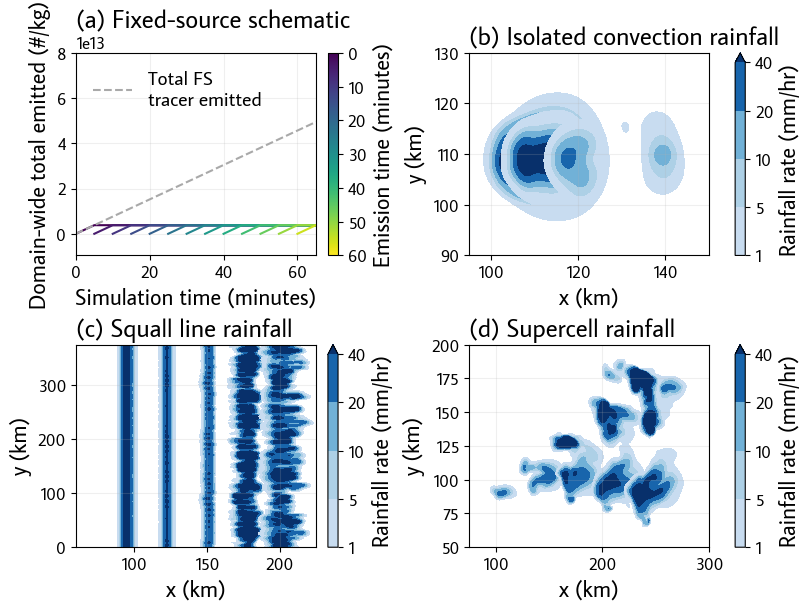

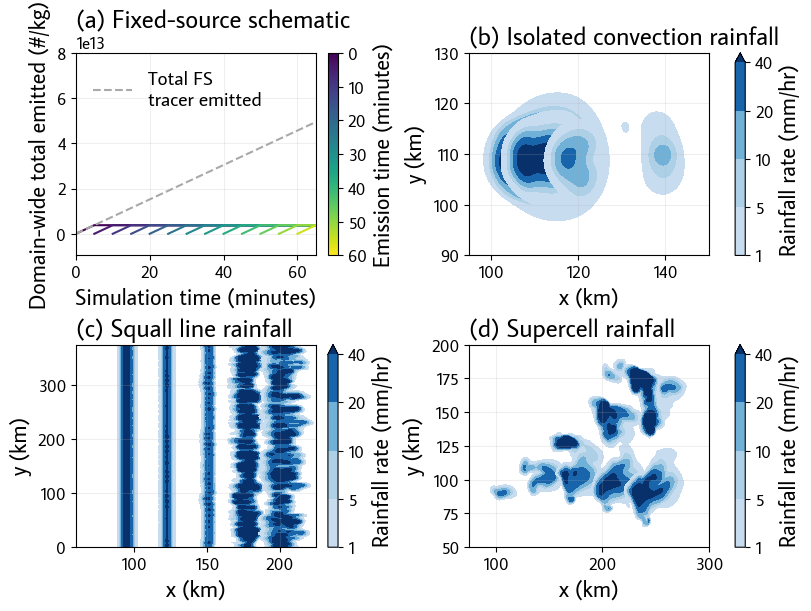

In [10]:
import matplotlib.ticker as ticker

figure_name = "f02_tracer_emission_schematic"
figure_data = {}

# Fixed source
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(8, 6), layout="constrained")

# Add an axes for a colorbar
# fig.subplots_adjust(right=0.95, hspace=0.2)  # Create space on the right hand side
# cbar_ax = plt.axes([0.98, 0.06, 0.03, 0.88])  # Add a small custom axis

storm_ds = storm_dss["sc_wk"]  # Since it doesn't matter

ax = axs.flatten()[0]
these_tracers = blt.FS_TRACERS[:13]
fs_species_lines = []

for tracer_ix, tracer in enumerate(these_tracers):
    # Want to mask all zero values besides the one right before it becomes not zero
    data = storm_ds["ACC" + tracer].sum(["x", "y"]).compute()
    first_nonzero = (data > 0).argmax("time").values
    data = data.isel({"time": slice(first_nonzero - 1, len(data["time"]))})
    fs_species_lines.append(
        blt.plot_and_save(
            figure_data,
            f"tracer-{tracer}_fs_total_emitted",
            ax.plot,
            data["t_minutes"].values,
            data.values,
            color=mpl.colormaps["viridis"](tracer_ix / len(these_tracers)),
        )[0]
    )

# Always set the vmin and vmax to 0 and 1
fs_cbar = fig.colorbar(
    mpl.cm.ScalarMappable(
        norm=mpl.colors.Normalize(vmin=0, vmax=1), cmap=blt.PROGRESSIVE_CMAP + "_r"
    ),
    ax=ax,
    orientation="vertical",
    label="Emission time (minutes)",
)
# fs_cbar = mpl.colorbar.ColorbarBase(
#     ax=ax,
#     cmap=blt.PROGRESSIVE_CMAP + "_r",
#     norm=mpl.colors.Normalize(vmin=0, vmax=1),
#     orientation="vertical",
# )
# Make the tick_values a linear range from 0 to 1 with the number of ticks you want
tick_labels = np.arange(0, 5 * len(these_tracers), 10)
tick_values = (tick_labels / tick_labels[-1])[::-1]
fs_cbar.set_ticks(tick_values)
fs_cbar.set_ticklabels(tick_labels)
# fs_cbar.ax.get_xaxis().labelpad = 10
# fs_cbar.ax.xaxis.set_label_position("top")
# fs_cbar.ax.set_xlabel("Emission time\n(minutes)")

total_line = blt.plot_and_save(
    figure_data,
    f"all_fs_total_emitted",
    ax.plot,
    storm_ds["t_minutes"].values,
    storm_ds["ACCtotal_fs_tracer"].sum(["x", "y"]).values,
    color="darkgrey",
    linestyle="dashed",
    label="Total FS\ntracer emitted",
)[0]

ax.set_xlim([0, 65])
ax.set_title("(a) Fixed-source schematic")
ax.set_ylim([-9572904127692.8, 8e13])
legend = ax.legend(handles=[total_line], loc="upper left")

ax.set_xlabel("Simulation time (minutes)")
ax.set_ylabel("Domain-wide total emitted (#/kg)")

ax_lims = {
    "ic_wk": {"x": [95000, 150000], "y": [90000, 130000]},
    "sl_wk": {"x": [60000, 225000], "y": None},
    "sc_wk": {"x": [75000, 300000], "y": [50000, 200000]},
}

for storm_ix, (storm, storm_ds) in enumerate(storm_dss.items()):
    ax = axs.flatten()[storm_ix + 1]

    for t_ix in range(0, len(storm_ds["time"]), 6):
        tracer_da = storm_ds.isel({"time": t_ix})
        artist = blt.plot_and_save(
            figure_data,
            f"storm-{storm}_tix-{t_ix}_pv_rainfall_rates",
            ax.contourf,
            tracer_da["x"].values,
            tracer_da["y"].values,
            tracer_da["PCPRR"].values,
            levels=blt.RS_TRACER_THRESHOLD_RAIN_RATES,
            cmap=cm.plotting.shifted_blues,
            extend="max",
        )

    these_lims = ax_lims[storm]
    if these_lims["x"]:
        ax.set_xlim(these_lims["x"])
    if these_lims["y"]:
        ax.set_ylim(these_lims["y"])
    cm.plotting.scale_axes_ticks(ax)
    ax.set_xlabel("x (km)")
    ax.set_ylabel("y (km)")
    ax.set_title(blt.axes_title(storm_ix + 1, f"{blt.STORM_LABELS[storm]} rainfall"))
    cbar = fig.colorbar(
        artist, ax=ax, orientation="vertical", label="Rainfall rate (mm/hr)"
    )
    cbar.set_ticklabels(blt.RS_TRACER_THRESHOLDS_MM_HR)

blt.save_figure_data(figure_data, figure_name)
cm.plotting.fig_multisave(fig, figure_name, blt.FIGS_DIR)

## Storm development figures

### Isolated convection

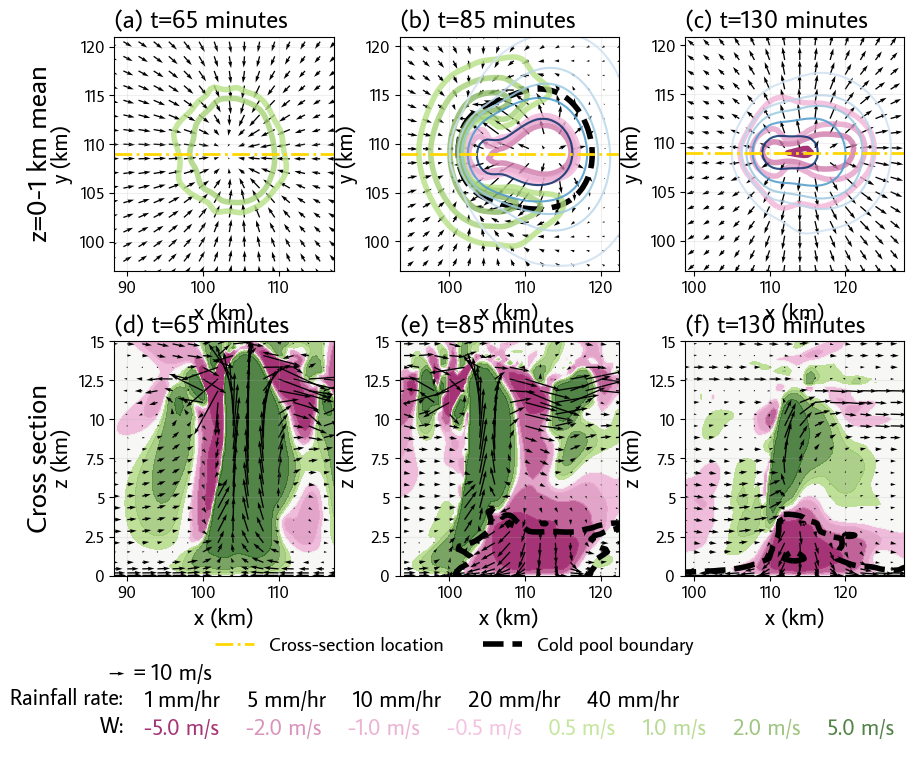

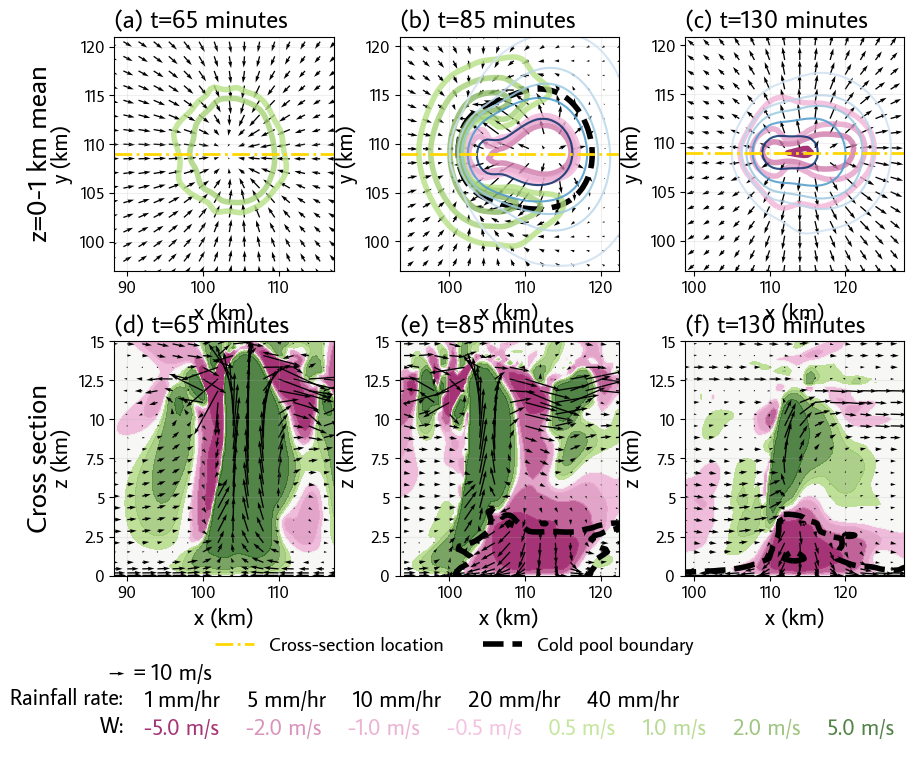

In [11]:
reload(cm.plotting)
reload(blt)

fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(10, 7))

fig.subplots_adjust(bottom=0.18, left=0.16)

# fig.subplots_adjust(left=0.15)
# fig.subplots_adjust(left=0.15, right=0.95)
# cbar_ax = plt.axes([0.96, 0.1, 0.04, 0.79])  # Add a small custom axis

storm_name = "ic_wk"
figure_data = {}
figure_name = f"f03_{storm_name}_storm_development"

development_times_minutes = [65, 85, 130]

x_offsets = [-6000, 0, -9000]
y_offsets = [0, 0, 1000]
cross_section_ys = [109000, 109000, 109000]

quiver_scale = 150
quiver_width = 0.006

updraft_levels = [-5, -2, -1, -0.5, 0.5, 1, 2, 5]
updraft_cmap = cm.plotting.sequential_cmap(
    [
        (0.0, mpl.colormaps["PiYG"](0)),
        (0.45, mpl.colormaps["PiYG"](0.3)),
        (0.5, mpl.colormaps["PiYG"](0.5)),
        (0.55, mpl.colormaps["PiYG"](0.7)),
        (1, mpl.colormaps["PiYG"](0.999)),
    ],
    N=512,
)
updraft_alpha = 0.8
pcprr_alpha = 0.85
legend_fontsize = 16

storm_ds = storm_dss[storm_name]

for t_ix, t_minutes in enumerate(development_times_minutes):
    pv_ax = axs[0, t_ix]
    xc_ax = axs[1, t_ix]

    this_time_storm_ds = storm_ds.sel(
        {"time": blt.minutes_to_simulation_time(t_minutes)}
    )
    # Calculate buoyancy
    this_time_storm_ds["theta_rho"] = this_time_storm_ds["THETA"] * (
        1 + 0.608 * this_time_storm_ds["RV"] - this_time_storm_ds["R_condensate"]
    )
    # And buoyancy
    tr_layer_mean = this_time_storm_ds["theta_rho"].mean(["x", "y"])
    this_time_storm_ds["buoyancy"] = (
        mpconstants.g
        * (this_time_storm_ds["theta_rho"] - tr_layer_mean)
        / tr_layer_mean
    ).pint.dequantify()
    this_time_storm_ds["buoyancy"] = this_time_storm_ds["buoyancy"].where(
        this_time_storm_ds["z"] <= 5000
    )

    # Calculate and set axes limits
    x_position = this_time_storm_ds["storm_position_x"] + x_offsets[t_ix]
    y_position = this_time_storm_ds["storm_position_y"] + y_offsets[t_ix]
    cross_section_y = cross_section_ys[t_ix] or y_position

    xlim = [x_position - 12000, x_position + 17000]
    ylim = [y_position - 12000, y_position + 12000]
    pv_ax.set_xlim(*xlim)
    xc_ax.set_xlim(*xlim)
    pv_ax.set_ylim(*ylim)
    xc_ax.set_ylim([0, 15000])

    quiver_x_spacing = (
        len(this_time_storm_ds["x"].sel({"x": slice(xlim[0], xlim[1] + 1)})["x"].values)
        // 18
    ) + 1
    quiver_y_spacing = (
        len(this_time_storm_ds["y"].sel({"y": slice(ylim[0], ylim[1] + 1)})["y"].values)
        // 18
    ) + 1

    this_01km_ds = (
        this_time_storm_ds.sel({"z": slice(0, 1000)})
        .mean("z")
        .sel(
            {
                "x": slice(xlim[0] - 1000, xlim[1] + 1000),
                "y": slice(ylim[0] - 1000, ylim[1] + 1000),
            }
        )
    )

    # Also will need to subset this to plot the winds
    quiver_x_spacing_01km = 4
    quiver_y_spacing_01km = 4
    this_01km_ds_quiver = this_01km_ds.isel(
        {
            "x": slice(0, len(this_01km_ds["x"]) + 1, quiver_x_spacing),
            "y": slice(0, len(this_01km_ds["y"]) + 1, quiver_y_spacing),
        }
    )

    ######### Plan view #########
    # Cold pool
    blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_pv_cp",
        pv_ax.contour,
        this_01km_ds["x"].values,
        this_01km_ds["y"].values,
        this_01km_ds["buoyancy"].values,
        levels=[-0.04],
        colors="black",
        linewidths=4,
        # alpha=0.8,
        linestyles="dashed",
    )
    # pv_ax.contour(
    #     *figure_data[data_name],
    #     levels=[-0.04],
    #     colors="black",
    #     linewidths=4,
    #     # alpha=0.8,
    #     linestyles="dashed",
    # )
    cp_line = pv_ax.plot(
        [],
        [],
        color="black",
        linewidth=4,
        linestyle="dashed",
        label="Cold pool boundary",
    )[0]

    # Updraft
    updraft_contours = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_pv_updraft",
        pv_ax.contour,
        this_01km_ds["x"].values,
        this_01km_ds["y"].values,
        this_01km_ds["WC"].values,
        levels=updraft_levels,
        # cmap="PiYG",
        cmap=updraft_cmap,
        alpha=updraft_alpha,
        linewidths=4,
    )

    # Rain
    pcprr_contours = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_pv_rain",
        pv_ax.contour,
        this_time_storm_ds["x"].values,
        this_time_storm_ds["y"].values,
        this_time_storm_ds["PCPRR"].values,
        levels=blt.RS_TRACER_THRESHOLD_RAIN_RATES,
        cmap=cm.plotting.shifted_blues,
        alpha=pcprr_alpha,
        extend="max",
    )

    # Wind
    blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_pv_wind",
        pv_ax.quiver,
        this_01km_ds_quiver["x"].values,
        this_01km_ds_quiver["y"].values,
        this_01km_ds_quiver["UC"].values,
        this_01km_ds_quiver["VC"].values,
        scale=quiver_scale,
        width=quiver_width,
    )

    # Cross section location
    xc_artist = pv_ax.axhline(
        cross_section_y,
        linestyle="dashdot",
        linewidth=2,
        color="gold",
        label="Cross-section location",
    )

    ######### Panel 4: cross section ##########

    this_xc_ds = this_time_storm_ds.sel({"y": cross_section_y}, method="nearest")

    # Cold pool
    blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_xc_cp",
        xc_ax.contour,
        this_xc_ds["x"].values,
        this_xc_ds["z"].values,
        this_xc_ds["buoyancy"].values,
        levels=[-0.04],
        colors="black",
        linewidths=4,
        # alpha=0.8,
        linestyles="dashed",
    )

    # Updraft
    blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_xc_updraft",
        xc_ax.contourf,
        this_xc_ds["x"].values,
        this_xc_ds["z"].values,
        this_xc_ds["WC"].values,
        levels=updraft_levels,
        cmap=updraft_cmap,
        extend="both",
        alpha=updraft_alpha,
    )

    # Wind
    quiver_x_spacing_xc = 4
    # For the cross section, need to take coarser stride in the slice at low levels, so just do this manually
    quiver_z_values_xc = np.concatenate(
        [
            storm_ds.sel({"z": slice(0, 1500)})["z"].values[::5],
            storm_ds.sel({"z": slice(1500, storm_ds["z"].max() + 1)})["z"].values[::3],
        ]
    )
    this_xc_ds_quiver = this_xc_ds.isel(
        {
            "x": slice(0, len(this_xc_ds["x"]) + 1, quiver_x_spacing),
        }
    ).sel({"z": quiver_z_values_xc})

    # Wind
    quiver = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_xc_wind",
        xc_ax.quiver,
        this_xc_ds_quiver["x"].values,
        this_xc_ds_quiver["z"].values,
        this_xc_ds_quiver["UC"].values,
        this_xc_ds_quiver["WC"].values,
        scale=quiver_scale,
        width=quiver_width,
    )

    # Labels
    pv_ax.set_title(blt.axes_title(t_ix, f"t={t_minutes} minutes"))
    xc_ax.set_title(blt.axes_title(3 + t_ix, f"t={t_minutes} minutes"))
    for ax in [pv_ax, xc_ax]:
        ax.set_xlabel("x (km)")
        cm.plotting.scale_axes_ticks(ax)
    pv_ax.set_ylabel("y (km)")
    xc_ax.set_ylabel("z (km)")


plt.legend(
    handles=[xc_artist, cp_line],
    loc="center",
    bbox_to_anchor=(0.5, 0.08),
    bbox_transform=fig.transFigure,
    ncols=2,
)

cm.plotting.add_row_header(
    axs[0, 0],
    "z=0-1 km mean",
    # xycoords="figure fraction",
    # xy=(0.05, 0.76),
)

cm.plotting.add_row_header(
    axs[1, 0],
    "Cross section",
    # xycoords="figure fraction",
    # xy=(0.05, 0.32),
)


quiverkey_speed = 10
axs[0, -1].quiverkey(
    Q=quiver,
    X=0.17,
    Y=0.04,
    U=quiverkey_speed,
    label=f"= {quiverkey_speed} m/s",
    coordinates="figure",
    labelpos="E",
    fontproperties={"size": legend_fontsize},
)

pcprr_legend = cm.plotting.contour_legend(
    pcprr_contours,
    labels=[f"{x} mm/hr" for x in blt.RS_TRACER_THRESHOLDS_MM_HR],
    labelcolor=pcprr_contours.get_facecolors(),
    bbox_to_anchor=(0.17, 0.045),
    bbox_transform=fig.transFigure,
    frameon=False,
    alignment="left",
    columnspacing=1.2,
    fontsize=legend_fontsize,
)
axs[0, 0].annotate(
    "Rainfall rate: ",
    xy=(0, 0),
    xycoords="figure fraction",
    xytext=(-5, 0),
    textcoords=mpl.text.OffsetFrom(pcprr_legend, (0, 0.4)),
    horizontalalignment="right",
    fontsize=legend_fontsize,
)

updraft_legend = cm.plotting.contour_legend(
    updraft_contours,
    labels=[f"{x} m/s" for x in updraft_contours.levels],
    labelcolor=updraft_contours.get_edgecolors(),
    bbox_to_anchor=(0.17, 0.005),
    bbox_transform=fig.transFigure,
    frameon=False,
    alignment="left",
    columnspacing=1.2,
    fontsize=legend_fontsize,
)
axs[0, 0].annotate(
    "W: ",
    xy=(0, 0),
    xycoords="figure fraction",
    xytext=(-5, 0),
    textcoords=mpl.text.OffsetFrom(updraft_legend, (0, 0.4)),
    horizontalalignment="right",
    fontsize=legend_fontsize,
)

blt.save_figure_data(figure_data, figure_name)
cm.plotting.fig_multisave(fig, figure_name, blt.FIGS_DIR)

### Squall line

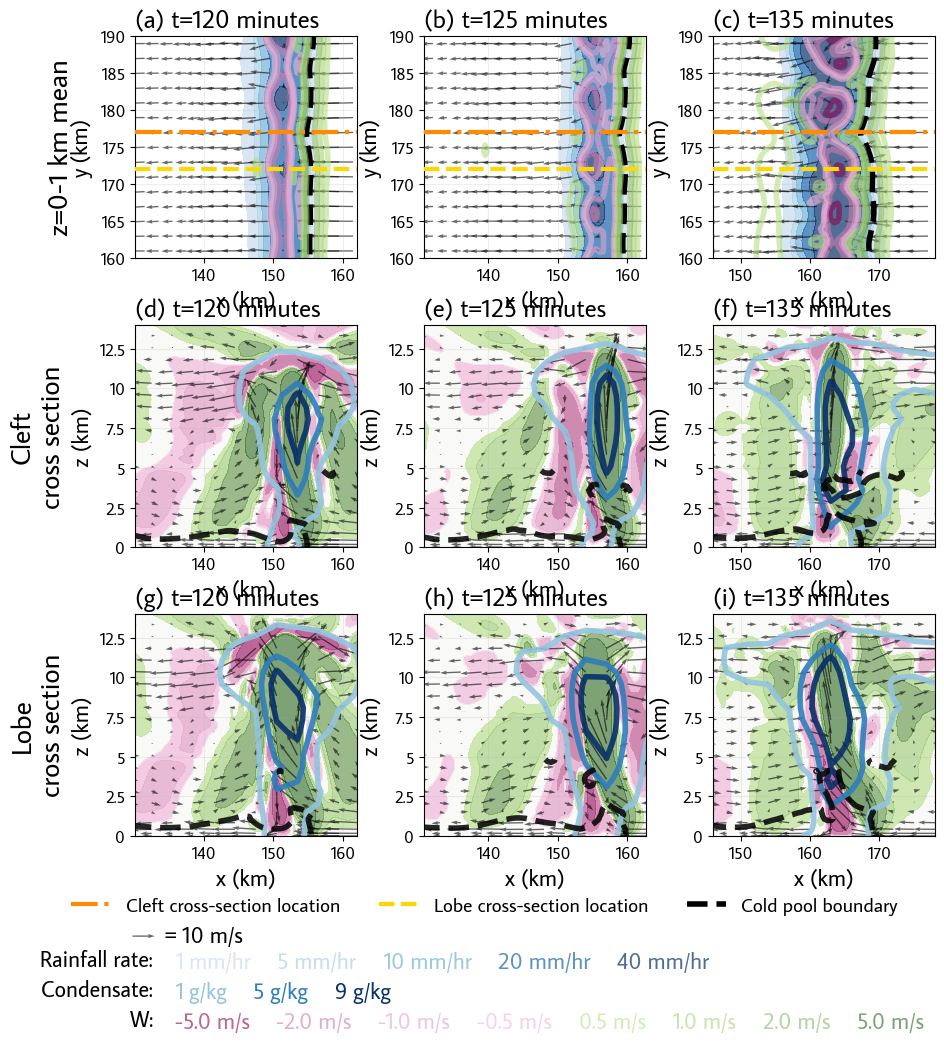

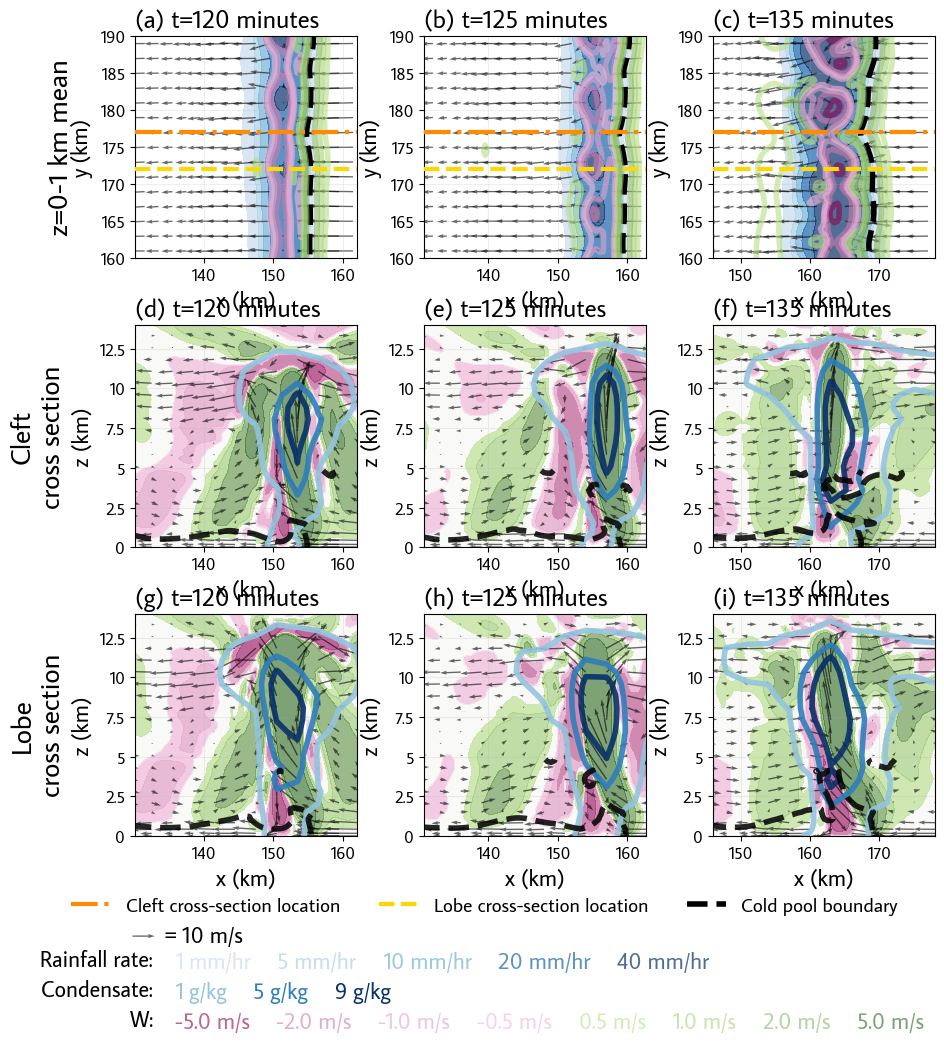

In [21]:
reload(cm.plotting)

storm_name = "sl_wk"
figure_data = {}
figure_name = f"f04_{storm_name}_storm_development"


development_df = development_dfs[storm_name]
storm_ds = storm_dss[storm_name]

development_df["storm_UC"] = (
    (development_df["storm_centroid_x"].diff() / 300).rolling(3).mean()
)

fig, axs = plt.subplots(nrows=3, ncols=3, figsize=(10, 10))

fig.subplots_adjust(left=0.15, bottom=0.15)
# fig.subplots_adjust(left=0.15, right=0.95)
# cbar_ax = plt.axes([0.96, 0.1, 0.04, 0.79])  # Add a small custom axis

lobe_y = 172000
cleft_y = 177000

development_times_minutes = [120, 125, 135]
# development_times_minutes = [70, 105, 155]

x_offsets = [-4000, -6000, 2000]
y_offsets = [0, 0, 0]
# cross_section_ys = [109000, 109000, 109000]

quiver_scale = 100
quiver_width = 0.006

updraft_levels = [-5, -2, -1, -0.5, 0.5, 1, 2, 5]
updraft_cmap = cm.plotting.sequential_cmap(
    [
        (0.0, mpl.colormaps["PiYG"](0)),
        (0.45, mpl.colormaps["PiYG"](0.3)),
        (0.5, mpl.colormaps["PiYG"](0.5)),
        (0.55, mpl.colormaps["PiYG"](0.7)),
        (1, mpl.colormaps["PiYG"](0.999)),
    ],
    N=512,
)
updraft_alpha = 0.6
pcprr_alpha = 0.85
legend_fontsize = 16

for t_ix, t_minutes in enumerate(development_times_minutes):

    this_time_storm_ds = storm_ds.sel(
        {"time": blt.minutes_to_simulation_time(t_minutes)}
    )
    # Cut out the upper level cold pool
    this_time_storm_ds["buoyancy"] = this_time_storm_ds["buoyancy"].where(
        this_time_storm_ds["z"] <= 5000
    )

    # Make U storm relative
    this_time_storm_ds["UC"] = (
        this_time_storm_ds["UC"]
        - development_df["storm_UC"]
        .loc[development_df["t_minutes"] == t_minutes]
        .values
    )

    # Calculate and set axes limits
    x_position = this_time_storm_ds["storm_position_x"] + x_offsets[t_ix]
    y_position = this_time_storm_ds["storm_position_y"] + y_offsets[t_ix]

    pv_ax = axs[0, t_ix]

    xlim = [x_position - 20000, x_position + 12000]
    ylim = [160000, 190000]
    pv_ax.set_xlim(*xlim)
    pv_ax.set_ylim(*ylim)
    for ax in axs[1:, t_ix].flatten():
        ax.set_ylim([0, 14000])
        ax.set_xlim(*xlim)

    quiver_x_spacing = (
        len(this_time_storm_ds["x"].sel({"x": slice(xlim[0], xlim[1] + 1)})["x"].values)
        // 18
    ) + 1
    quiver_y_spacing = (
        len(this_time_storm_ds["y"].sel({"y": slice(ylim[0], ylim[1] + 1)})["y"].values)
        // 18
    ) + 1
    quiver_alpha = 0.6

    this_01km_ds = (
        this_time_storm_ds.sel({"z": slice(0, 1000)})
        .mean("z")
        .sel(
            {
                "x": slice(xlim[0] - 1000, xlim[1] + 1000),
                "y": slice(ylim[0] - 1000, ylim[1] + 1000),
            }
        )
    )

    # Also will need to subset this to plot the winds
    quiver_x_spacing_01km = 4
    quiver_y_spacing_01km = 4
    this_01km_ds_quiver = this_01km_ds.isel(
        {
            "x": slice(0, len(this_01km_ds["x"]) + 1, quiver_x_spacing),
            "y": slice(0, len(this_01km_ds["y"]) + 1, quiver_y_spacing),
        }
    )

    ######### Plan view #########
    cp_style_kwargs = {"colors": "black", "linewidths": 4, "linestyles": "dashed"}
    # Cold pool
    pv_ax.contour(
        this_01km_ds["x"],
        this_01km_ds["y"],
        this_01km_ds["buoyancy"],
        levels=[-0.04],
        **cp_style_kwargs,
    )
    # Also make a fake line with the same style for the legend
    cp_line = ax.plot(
        [],
        [],
        label="Cold pool boundary",
        color="black",
        linewidth=4,
        linestyle="dashed",
    )[0]

    # Updraft

    updraft_contours = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_pv_updraft",
        pv_ax.contour,
        this_01km_ds["x"],
        this_01km_ds["y"],
        this_01km_ds["WC"],
        levels=updraft_levels,
        cmap=updraft_cmap,
        alpha=updraft_alpha,
        linewidths=4,
    )

    # Rain
    pcprr_contours = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_pv_rain",
        pv_ax.contourf,
        this_time_storm_ds["x"],
        this_time_storm_ds["y"],
        this_time_storm_ds["PCPRR"],
        levels=blt.RS_TRACER_THRESHOLD_RAIN_RATES,
        cmap=cm.plotting.shifted_blues,
        alpha=0.7,
        extend="max",
    )

    # Wind
    blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_pv_wind",
        pv_ax.quiver,
        this_01km_ds_quiver["x"],
        this_01km_ds_quiver["y"],
        this_01km_ds_quiver["UC"],
        this_01km_ds_quiver["VC"],
        scale=quiver_scale,
        width=quiver_width,
        alpha=quiver_alpha,
    )

    # Cross section lines
    lobe_line = pv_ax.axhline(
        lobe_y,
        linewidth=3,
        color="gold",
        linestyle="dashed",
        zorder=999,
        label="Lobe cross-section location",
    )
    cleft_line = pv_ax.axhline(
        cleft_y,
        linewidth=3,
        color="darkorange",
        linestyle="dashdot",
        zorder=999,
        label="Cleft cross-section location",
    )

    ########## Cross sections ##########

    for xc_y_ix, xc_y in enumerate([cleft_y, lobe_y]):

        cl_label = ["cleft", "lobe"][xc_y_ix]

        this_xc_ds = this_time_storm_ds.sel({"y": xc_y}, method="nearest").sel(
            {"x": slice(xlim[0] - 1000, xlim[1] + 1000), "z": slice(0, 15000)}
        )
        xc_ax = axs[xc_y_ix + 1, t_ix]

        # Cold pool
        blt.plot_and_save(
            figure_data,
            f"storm-{storm}_t-{t_minutes}_xc-{cl_label}_cp",
            xc_ax.contour,
            this_xc_ds["x"],
            this_xc_ds["z"],
            this_xc_ds["buoyancy"],
            levels=[-0.04],
            colors="black",
            # colors=[mpl.colormaps["Greys"](0.7)],
            linewidths=4,
            alpha=0.85,
            linestyles="dashed",
            # dashes=(5, 5),
            zorder=999,
        )

        # Updraft
        blt.plot_and_save(
            figure_data,
            f"storm-{storm}_t-{t_minutes}_xc-{cl_label}_updraft",
            xc_ax.contourf,
            this_xc_ds["x"],
            this_xc_ds["z"],
            this_xc_ds["WC"],
            levels=updraft_levels,
            cmap=updraft_cmap,
            alpha=updraft_alpha,
            extend="both",
        )

        # Wind
        quiver_x_spacing_xc = 4
        # For the cross section, need to take coarser stride in the slice at low levels, so just do this manually
        quiver_z_values_xc = np.concatenate(
            [
                storm_ds.sel({"z": slice(0, 1500)})["z"].values[::5],
                storm_ds.sel({"z": slice(1500, this_xc_ds["z"].max() + 1)})["z"].values[
                    ::3
                ],
            ]
        )
        this_xc_ds_quiver = this_xc_ds.isel(
            {
                "x": slice(0, len(this_xc_ds["x"]) + 1, quiver_x_spacing + 2),
            }
        ).sel({"z": quiver_z_values_xc})

        # Wind
        quiver = blt.plot_and_save(
            figure_data,
            f"storm-{storm}_t-{t_minutes}_xc-{cl_label}_wind",
            xc_ax.quiver,
            this_xc_ds_quiver["x"],
            this_xc_ds_quiver["z"],
            this_xc_ds_quiver["UC"],
            this_xc_ds_quiver["WC"],
            scale=quiver_scale,
            width=quiver_width,
            alpha=quiver_alpha,
        )

        # Condensate
        condensate_contours = blt.plot_and_save(
            figure_data,
            f"storm-{storm}_t-{t_minutes}_xc-{cl_label}_condensate",
            xc_ax.contour,
            this_xc_ds_quiver["x"],
            this_xc_ds_quiver["z"],
            this_xc_ds_quiver["R_condensate"],
            cmap=cm.plotting.shifted_colormap("Blues", [0.4, 1]),
            levels=np.arange(0.001, 0.0091, 0.004),
            alpha=0.9,
            linewidths=4,
            # linestyles="dashdot",
        )

    # Labels
    pv_ax.set_title(blt.axes_title(t_ix, f"t={t_minutes} minutes"))
    axs[1, t_ix].set_title(blt.axes_title(3 + t_ix, f"t={t_minutes} minutes"))
    axs[2, t_ix].set_title(blt.axes_title(6 + t_ix, f"t={t_minutes} minutes"))
    pv_ax.set_ylabel("y (km)")
    for ax in axs[:, t_ix]:
        ax.set_xlabel("x (km)")
        cm.plotting.scale_axes_ticks(ax)
    for ax in axs[1:, t_ix]:
        ax.set_ylabel("z (km)")

cm.plotting.add_row_header(
    axs[0, 0],
    "z=0-1 km mean",
    # xycoords="figure fraction",
    # xy=(0.05, 0.85),
)

cm.plotting.add_row_header(axs[1, 0], "Cleft\ncross section", pad=20)

cm.plotting.add_row_header(axs[2, 0], "Lobe\ncross section", pad=20)

plt.legend(
    handles=[cleft_line, lobe_line, cp_line],
    loc="center",
    bbox_to_anchor=(0.5, 0.08),
    bbox_transform=fig.transFigure,
    # frameon=True,
    # facecolor="whitesmoke",
    # framealpha=0.7,
    ncols=3,
)

quiverkey_speed = 10
axs[-1, 0].quiverkey(
    Q=quiver,
    X=0.17,
    Y=0.05,
    U=quiverkey_speed,
    label=f"= {quiverkey_speed} m/s",
    coordinates="figure",
    labelpos="E",
    fontproperties={"size": legend_fontsize},
)

pcprr_legend = cm.plotting.contour_legend(
    pcprr_contours,
    labels=[f"{x} mm/hr" for x in blt.RS_TRACER_THRESHOLDS_MM_HR],
    labelcolor=pcprr_contours.get_facecolors(),
    bbox_to_anchor=(0.17, 0.055),
    bbox_transform=fig.transFigure,
    frameon=False,
    alignment="left",
    columnspacing=1.2,
    fontsize=legend_fontsize,
)
axs[-1, 0].annotate(
    "Rainfall rate: ",
    xy=(0, 0),
    xycoords="figure fraction",
    xytext=(-5, 0),
    textcoords=mpl.text.OffsetFrom(pcprr_legend, (0, 0.4)),
    horizontalalignment="right",
    fontsize=legend_fontsize,
)

updraft_legend = cm.plotting.contour_legend(
    updraft_contours,
    labels=[f"{x} m/s" for x in updraft_contours.levels],
    labelcolor=updraft_contours.get_edgecolors(),
    bbox_to_anchor=(0.17, -0.005),
    bbox_transform=fig.transFigure,
    frameon=False,
    alignment="left",
    columnspacing=1.2,
    fontsize=legend_fontsize,
)

axs[-1, 0].annotate(
    "W: ",
    xy=(0, 0),
    xycoords="figure fraction",
    xytext=(-5, 0),
    textcoords=mpl.text.OffsetFrom(updraft_legend, (0, 0.4)),
    horizontalalignment="right",
    fontsize=legend_fontsize,
)


condensate_legend = cm.plotting.contour_legend(
    condensate_contours,
    labels=[f"{x*1000:.0f} g/kg" for x in condensate_contours.levels],
    labelcolor=[(c[0], c[1], c[2], 1) for c in condensate_contours.get_edgecolors()],
    bbox_to_anchor=(0.17, 0.025),
    bbox_transform=fig.transFigure,
    frameon=False,
    alignment="left",
    columnspacing=1.2,
    fontsize=legend_fontsize,
)
axs[-1, 0].annotate(
    "Condensate: ",
    xy=(0, 0),
    xycoords="figure fraction",
    xytext=(-5, 0),
    textcoords=mpl.text.OffsetFrom(condensate_legend, (0, 0.4)),
    horizontalalignment="right",
    fontsize=legend_fontsize,
)

blt.save_figure_data(figure_data, figure_name)
cm.plotting.fig_multisave(fig, figure_name, blt.FIGS_DIR)

### Supercell

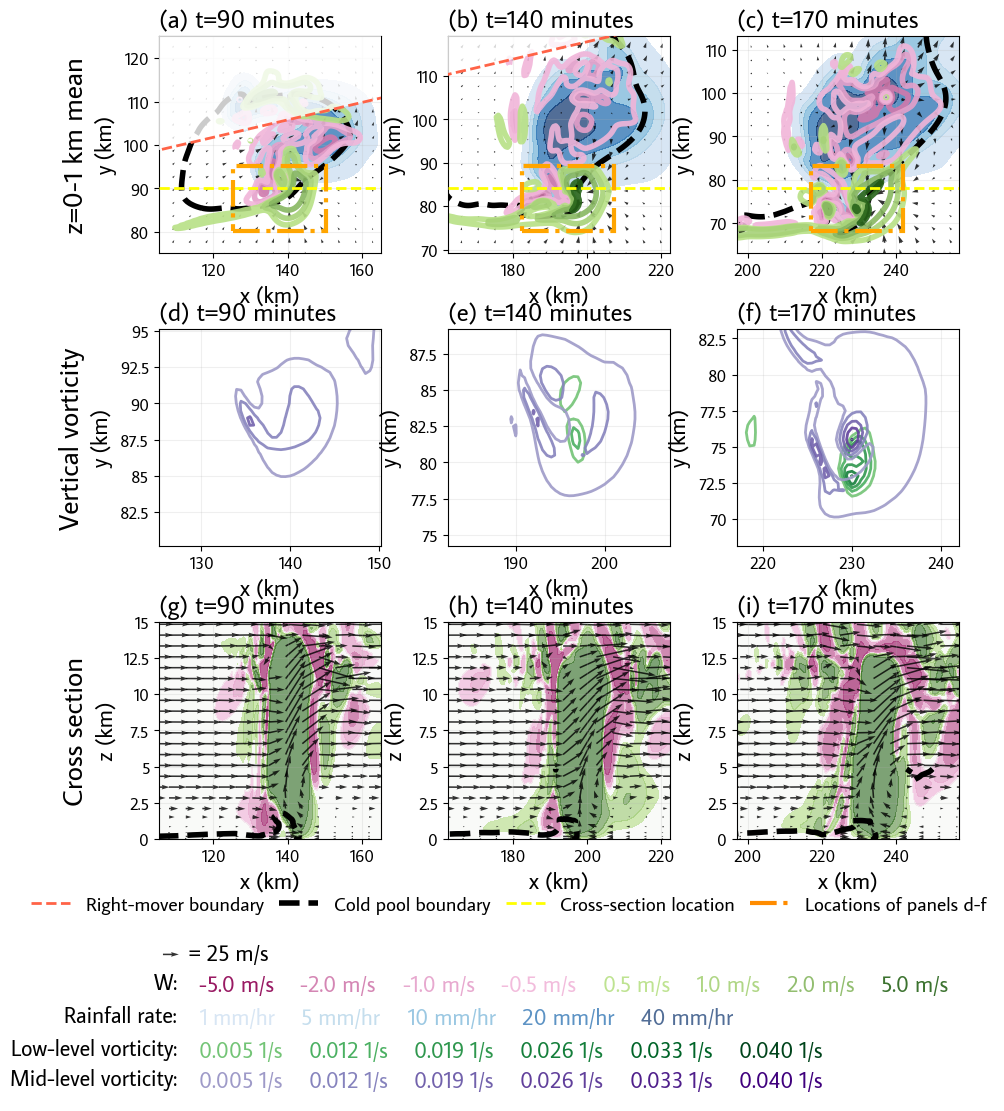

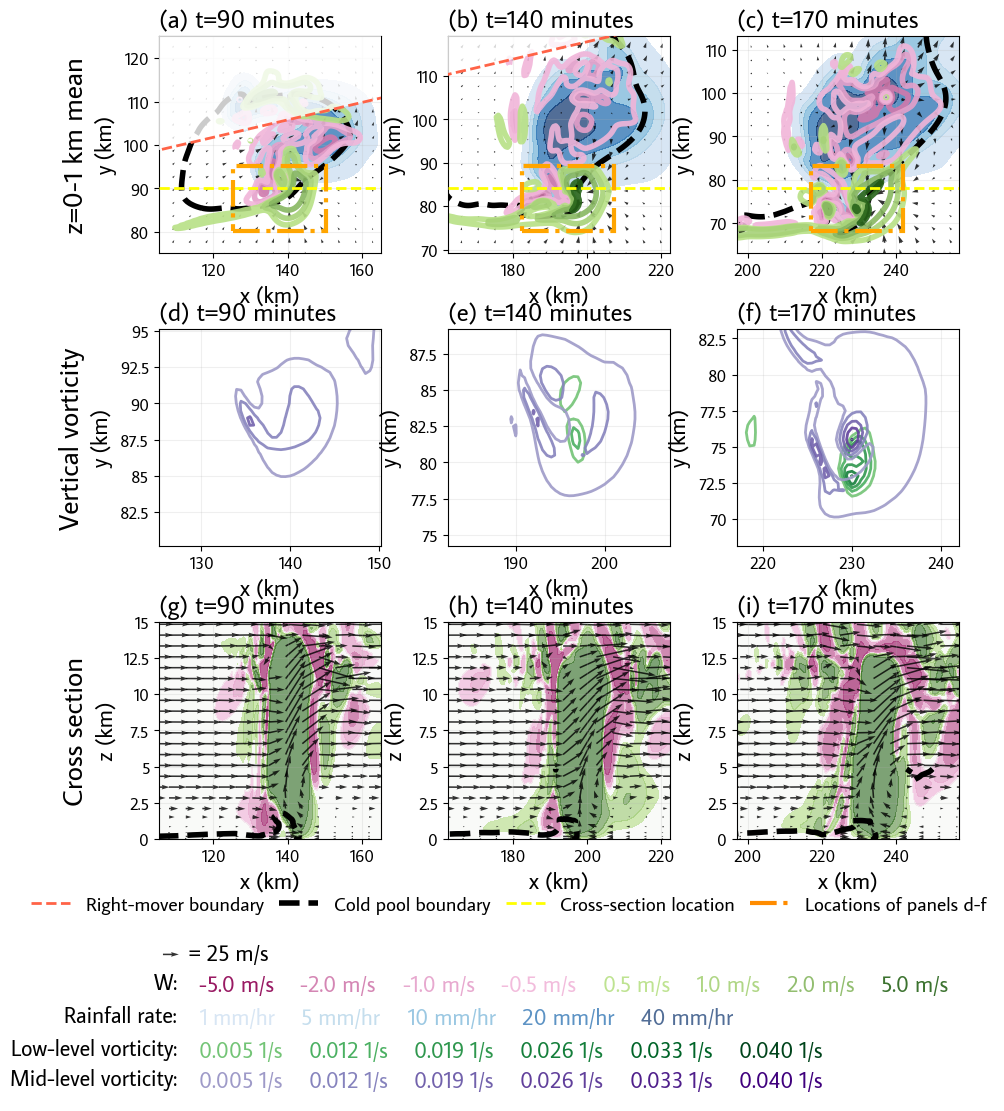

In [22]:
reload(cm.plotting)

fig, axs = plt.subplots(nrows=3, ncols=3, figsize=(10, 11))

fig.subplots_adjust(left=0.15, bottom=0.22, hspace=0.35)
# fig.subplots_adjust(left=0.15, right=0.95)
# cbar_ax = plt.axes([0.96, 0.1, 0.04, 0.79])  # Add a small custom axis

storm_name = "sc_wk"
figure_name = f"f05_{storm_name}_storm_development"
figure_data = {}

storm_ds = storm_dss[storm_name]
development_df = development_dfs[storm_name]

# Calculate vertical vorticity
storm_ds["vertical_vorticity"] = storm_ds["VC"].differentiate("x") - storm_ds[
    "UC"
].differentiate("y")

development_times_minutes = [90, 140, 170]

x_offsets = [0, 0, 0]
y_offsets = [0, 0, 0]
cross_section_ys = [None, None, None]

quiver_scale = 350
quiver_width = 0.007

updraft_levels = [-5, -2, -1, -0.5, 0.5, 1, 2, 5]
updraft_cmap = cm.plotting.sequential_cmap(
    [
        (0.0, mpl.colormaps["PiYG"](0)),
        (0.45, mpl.colormaps["PiYG"](0.3)),
        (0.5, mpl.colormaps["PiYG"](0.5)),
        (0.55, mpl.colormaps["PiYG"](0.7)),
        (1, mpl.colormaps["PiYG"](0.999)),
    ],
    N=512,
)
updraft_alpha = 0.6
pcprr_alpha = 0.85
legend_fontsize = 16
lm_boundary_edgecolor = "tomato"


def lm_polygon():
    return plt.Polygon(
        [
            (storm_ds["x"].min(), blt.sc_wk_right_mover_boundary(storm_ds["x"].min())),
            (storm_ds["x"].min(), storm_ds["y"].max()),
            (storm_ds["x"].max(), storm_ds["y"].max()),
            (storm_ds["x"].max(), blt.sc_wk_right_mover_boundary(storm_ds["x"].max())),
        ],
        closed=True,
        facecolor=(1, 1, 1, 0.8),
        edgecolor=lm_boundary_edgecolor,
        linestyle="dashed",
        linewidth=2,
        zorder=999,
    )


for ax in axs[:2, :].flatten():
    ax.add_patch(lm_polygon())
    lm_boundary_line = ax.plot(
        [],
        [],
        color=lm_boundary_edgecolor,
        linestyle="dashed",
        linewidth=2,
        label="Right-mover boundary",
    )[0]

for t_ix, t_minutes in enumerate(development_times_minutes):

    this_time_storm_ds = storm_ds.sel(
        {"time": blt.minutes_to_simulation_time(t_minutes)}
    )
    # Filter to low-level cold pool
    this_time_storm_ds["buoyancy"] = this_time_storm_ds["buoyancy"].where(
        this_time_storm_ds["z"] <= 5000
    )

    # Calculate and set axes limits
    x_position = this_time_storm_ds["storm_position_x"] + x_offsets[t_ix]
    y_position = this_time_storm_ds["storm_position_y"] + y_offsets[t_ix]
    cross_section_y = cross_section_ys[t_ix] or y_position

    xlim = [x_position - 35000, x_position + 25000]
    ylim = [y_position - 15000, y_position + 35000]
    for ax in axs[:, t_ix]:
        ax.set_xlim(*xlim)
    for ax in axs[:2, t_ix]:
        ax.set_ylim(*ylim)
    axs[2, t_ix].set_ylim([0, 15000])

    quiver_x_spacing = (
        len(this_time_storm_ds["x"].sel({"x": slice(xlim[0], xlim[1] + 1)})["x"].values)
        // 18
    ) + 1
    quiver_y_spacing = (
        len(this_time_storm_ds["y"].sel({"y": slice(ylim[0], ylim[1] + 1)})["y"].values)
        // 18
    ) + 1

    this_01km_ds = (
        this_time_storm_ds.sel({"z": slice(0, 1000)})
        .mean("z")
        .sel(
            {
                "x": slice(xlim[0] - 1000, xlim[1] + 1000),
                "y": slice(ylim[0] - 1000, ylim[1] + 1000),
            }
        )
    )

    # Also will need to subset this to plot the winds
    quiver_alpha = 0.8

    this_01km_ds_quiver = this_01km_ds.isel(
        {
            "x": slice(0, len(this_01km_ds["x"]) + 1, quiver_x_spacing + 2),
            "y": slice(0, len(this_01km_ds["y"]) + 1, quiver_y_spacing),
        }
    )

    ######### Plan view #########

    # Cold pool
    pv_ax = axs[0, t_ix]
    blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_pv_cp",
        pv_ax.contour,
        this_01km_ds["x"],
        this_01km_ds["y"],
        this_01km_ds["buoyancy"],
        levels=[-0.04],
        colors="black",
        linewidths=4,
        # alpha=0.8,
        linestyles="dashed",
    )
    cp_line = pv_ax.plot(
        [],
        [],
        color="black",
        linewidth=4,
        linestyle="dashed",
        label="Cold pool boundary",
    )[0]

    # Updraft
    updraft_contours = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_pv_updraft",
        pv_ax.contour,
        this_01km_ds["x"],
        this_01km_ds["y"],
        this_01km_ds["WC"],
        levels=updraft_levels,
        # cmap="PiYG",
        cmap=updraft_cmap,
        alpha=0.9,
        linewidths=4,
    )

    # Rain
    pcprr_contours = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_pv_rain",
        pv_ax.contourf,
        this_time_storm_ds["x"],
        this_time_storm_ds["y"],
        this_time_storm_ds["PCPRR"],
        levels=blt.RS_TRACER_THRESHOLD_RAIN_RATES,
        cmap=cm.plotting.shifted_blues,
        alpha=0.7,
        extend="max",
    )

    # Wind
    blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_pv_wind",
        pv_ax.quiver,
        this_01km_ds_quiver["x"],
        this_01km_ds_quiver["y"],
        this_01km_ds_quiver["UC"],
        this_01km_ds_quiver["VC"],
        scale=quiver_scale,
        width=quiver_width,
        alpha=quiver_alpha,
    )

    # Add a line indicating the cross section
    xc_line = pv_ax.axhline(
        cross_section_y,
        linewidth=2,
        color="yellow",
        linestyle="dashed",
        zorder=999,
        label="Cross-section location",
    )

    ########## Vorticity ##########

    # Vertical vorticity
    # Low level
    vorticity_ax = axs[1, t_ix]
    low_vorticity_contours = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_vorticity_low",
        vorticity_ax.contour,
        this_01km_ds["x"],
        this_01km_ds["y"],
        this_01km_ds["vertical_vorticity"],
        cmap=cm.plotting.shifted_colormap("Greens", [0.5, 1]),
        levels=np.arange(0.005, 0.041, 0.007),
        alpha=0.9,
        linewidths=2,
    )
    # Midlevel
    this_5km_ds = this_time_storm_ds.sel({"z": 5000}, method="nearest")
    mid_vorticity_contours = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_vorticity_mid",
        vorticity_ax.contour,
        this_5km_ds["x"],
        this_5km_ds["y"],
        this_5km_ds["vertical_vorticity"],
        cmap=cm.plotting.shifted_colormap("Purples", [0.5, 1]),
        levels=np.arange(0.005, 0.041, 0.007),
        alpha=0.9,
        # linestyles="dashed",
        linewidths=2,
    )

    # Set the limits and add squares on panels 1 and 2
    vorticity_ax.set_xlim(xlim[0] + 20000, xlim[1] - 15000)
    vorticity_ax.set_ylim(ylim[0] + 5000, ylim[1] - 30000)

    def rectangle_patch():
        return mpl.patches.Rectangle(
            xy=(vorticity_ax.get_xlim()[0], vorticity_ax.get_ylim()[0]),
            width=vorticity_ax.get_xlim()[1] - vorticity_ax.get_xlim()[0],
            height=vorticity_ax.get_ylim()[1] - vorticity_ax.get_ylim()[0],
            linestyle="dashdot",
            linewidth=3,
            edgecolor="orange",
            facecolor=(0, 0, 0, 0),
            zorder=999,
        )

    pv_ax.add_patch(rectangle_patch())
    vorticity_area_line = pv_ax.plot(
        [],
        [],
        linestyle="dashdot",
        color="darkorange",
        linewidth=3,
        label="Locations of panels d-f",
    )[0]

    ########## Cross section ##########

    this_xc_ds = this_time_storm_ds.sel({"y": cross_section_y}, method="nearest")
    xc_ax = axs[2, t_ix]

    # Cold pool
    blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_xc_cp",
        xc_ax.contour,
        this_xc_ds["x"],
        this_xc_ds["z"],
        this_xc_ds["buoyancy"],
        levels=[-0.04],
        colors="black",
        linewidths=4,
        # alpha=0.8,
        linestyles="dashed",
    )

    # Updraft
    blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_xc_updraft",
        xc_ax.contourf,
        this_xc_ds["x"],
        this_xc_ds["z"],
        this_xc_ds["WC"],
        levels=updraft_levels,
        # cmap="PiYG",
        cmap=updraft_cmap,
        alpha=updraft_alpha,
        extend="both",
    )

    # Wind
    # For the cross section, need to take coarser stride in the slice at low levels, so just do this manually
    quiver_z_values_xc = np.concatenate(
        [
            storm_ds.sel({"z": slice(0, 1500)})["z"].values[::5],
            storm_ds.sel({"z": slice(1500, storm_ds["z"].max() + 1)})["z"].values[::3],
        ]
    )
    this_xc_ds_quiver = this_xc_ds.isel(
        {
            "x": slice(0, len(this_xc_ds["x"]) + 1, quiver_x_spacing + 2),
        }
    ).sel({"z": quiver_z_values_xc})

    # Wind
    quiver = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_xc_wind",
        xc_ax.quiver,
        this_xc_ds_quiver["x"],
        this_xc_ds_quiver["z"],
        this_xc_ds_quiver["UC"],
        this_xc_ds_quiver["WC"],
        scale=quiver_scale,
        width=quiver_width,
        alpha=quiver_alpha,
    )

    # Labels
    pv_ax.set_title(blt.axes_title(t_ix, f"t={t_minutes} minutes"))
    vorticity_ax.set_title(blt.axes_title(3 + t_ix, f"t={t_minutes} minutes"))
    xc_ax.set_title(blt.axes_title(6 + t_ix, f"t={t_minutes} minutes"))

    for ax in axs[:, t_ix]:
        ax.set_xlabel("x (km)")
        cm.plotting.scale_axes_ticks(ax)
    pv_ax.set_ylabel("y (km)")
    vorticity_ax.set_ylabel("y (km)")
    xc_ax.set_ylabel("z (km)")


# plt.tight_layout()

cm.plotting.add_row_header(axs[0, 0], "z=0-1 km mean", pad=10)

cm.plotting.add_row_header(axs[1, 0], "Vertical vorticity", pad=10)

cm.plotting.add_row_header(axs[2, 0], "Cross section", pad=10)

plt.legend(
    handles=[lm_boundary_line, cp_line, xc_line, vorticity_area_line],
    loc="center",
    bbox_to_anchor=(0.5, 0.16),
    bbox_transform=fig.transFigure,
    ncols=4,
    columnspacing=0.8,
)

quiverkey_speed = 25
axs[-1, 0].quiverkey(
    Q=quiver,
    X=0.17,
    Y=0.115,
    U=quiverkey_speed,
    label=f"= {quiverkey_speed} m/s",
    coordinates="figure",
    labelpos="E",
    fontproperties={"size": legend_fontsize},
)

column_spacing = 1.2

updraft_legend = cm.plotting.contour_legend(
    updraft_contours,
    labels=[f"{x} m/s" for x in updraft_contours.levels],
    labelcolor=updraft_contours.get_edgecolors(),
    bbox_to_anchor=(0.17, 0.115),
    bbox_transform=fig.transFigure,
    frameon=False,
    alignment="left",
    columnspacing=column_spacing,
    fontsize=legend_fontsize,
)
# axs[0, 0].annotate(
#     "W: ", xy=(0.17, 0.088), xycoords=fig.transFigure, horizontalalignment="right", fontsize=legend_fontsize
# )
axs[-1, 0].annotate(
    "W: ",
    xy=(0, 0),
    xycoords="figure fraction",
    xytext=(-5, 0),
    textcoords=mpl.text.OffsetFrom(updraft_legend, (0, 0.4)),
    horizontalalignment="right",
    fontsize=legend_fontsize,
)
pcprr_legend = cm.plotting.contour_legend(
    pcprr_contours,
    labels=[f"{x} mm/hr" for x in blt.RS_TRACER_THRESHOLDS_MM_HR],
    labelcolor=pcprr_contours.get_facecolors(),
    bbox_to_anchor=(0.17, 0.085),
    bbox_transform=fig.transFigure,
    frameon=False,
    alignment="left",
    columnspacing=column_spacing,
    fontsize=legend_fontsize,
)
# axs[0, 0].annotate(
#     "Rainfall rate: ",
#     xy=(0.17, 0.0575),
#     xycoords=fig.transFigure,
#     horizontalalignment="right",
#     fontsize=legend_fontsize,
# )
axs[-1, 0].annotate(
    "Rainfall rate: ",
    xy=(0, 0),
    xycoords="figure fraction",
    xytext=(-5, 0),
    textcoords=mpl.text.OffsetFrom(pcprr_legend, (0, 0.4)),
    horizontalalignment="right",
    fontsize=legend_fontsize,
)

low_vorticity_legend = cm.plotting.contour_legend(
    low_vorticity_contours,
    labels=[f"{x:.3f} 1/s" for x in low_vorticity_contours.levels],
    labelcolor=[(c[0], c[1], c[2], 1) for c in low_vorticity_contours.get_edgecolors()],
    bbox_to_anchor=(0.17, 0.055),
    bbox_transform=fig.transFigure,
    frameon=False,
    alignment="left",
    columnspacing=column_spacing,
    fontsize=legend_fontsize,
)
# axs[0, 0].annotate(
#     "Low-level vorticity: ",
#     xy=(0.17, 0.03),
#     xycoords=fig.transFigure,
#     horizontalalignment="right",
#     fontsize=legend_fontsize,
# )
axs[-1, 0].annotate(
    "Low-level vorticity: ",
    xy=(0, 0),
    xycoords="figure fraction",
    xytext=(-5, 0),
    textcoords=mpl.text.OffsetFrom(low_vorticity_legend, (0, 0.4)),
    horizontalalignment="right",
    fontsize=legend_fontsize,
)


mid_vorticity_legend = cm.plotting.contour_legend(
    mid_vorticity_contours,
    labels=[f"{x:.3f} 1/s" for x in mid_vorticity_contours.levels],
    labelcolor=[(c[0], c[1], c[2], 1) for c in mid_vorticity_contours.get_edgecolors()],
    bbox_to_anchor=(0.17, 0.028),
    bbox_transform=fig.transFigure,
    frameon=False,
    alignment="left",
    columnspacing=column_spacing,
    fontsize=legend_fontsize,
)
# axs[0, 0].annotate(
#     "Mid-level vorticity: ",
#     xy=(0.17, 0.003),
#     xycoords=fig.transFigure,
#     horizontalalignment="right",
#     fontsize=legend_fontsize,
# )
axs[-1, 0].annotate(
    "Mid-level vorticity: ",
    xy=(0, 0),
    xycoords="figure fraction",
    xytext=(-5, 0),
    textcoords=mpl.text.OffsetFrom(mid_vorticity_legend, (0, 0.4)),
    horizontalalignment="right",
    fontsize=legend_fontsize,
)


blt.save_figure_data(figure_data, figure_name)
cm.plotting.fig_multisave(fig, figure_name, blt.FIGS_DIR, extensions=[".pdf", ".png"])

## Storm development stats

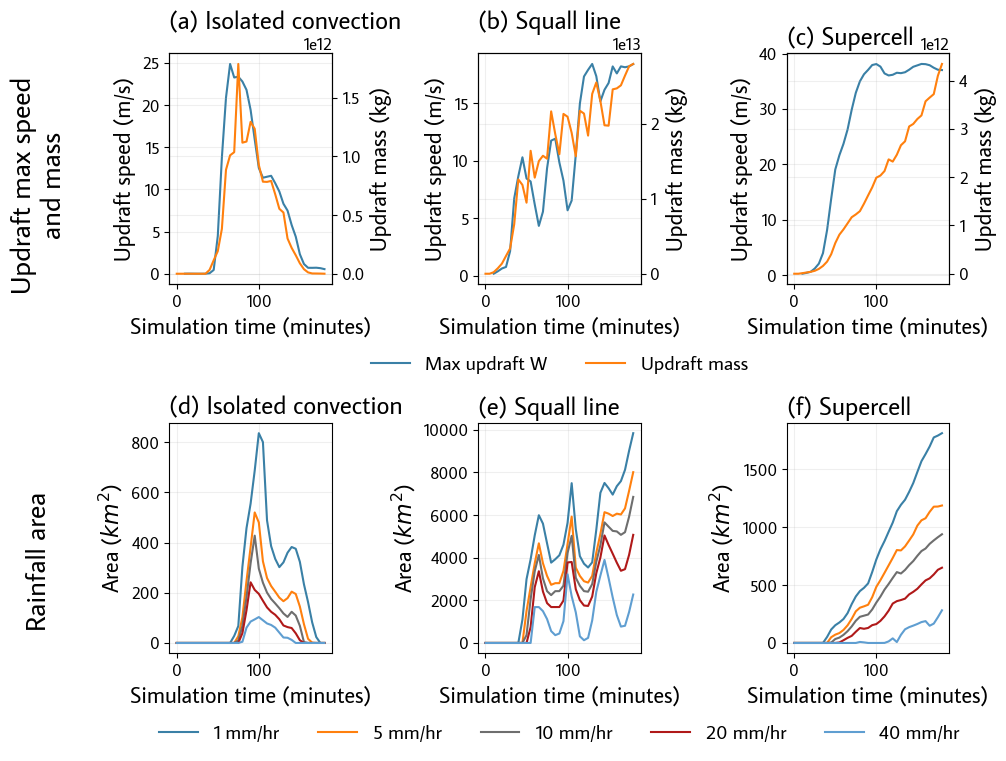

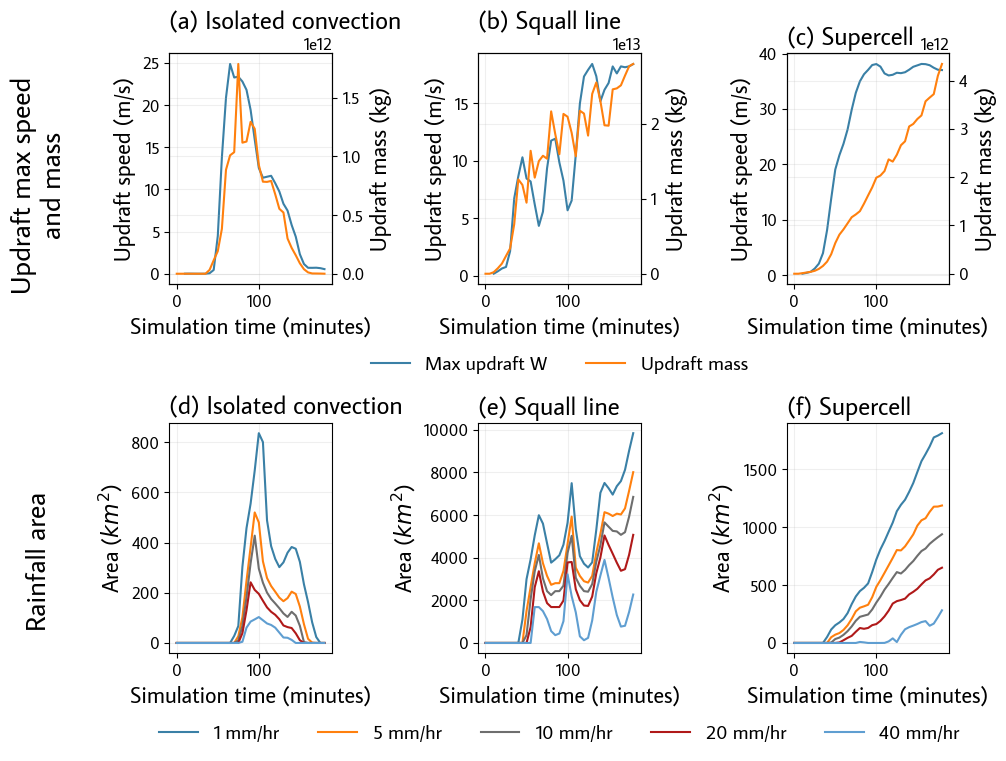

In [14]:
fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(10, 8))
fig.subplots_adjust(hspace=0.6, left=0.17, wspace=0.9, bottom=0.2)

storm_dev_stats = {}

updraft_axs = []

figure_name = f"f09_storm_development_stats"
figure_data = {}


def ss_max_w(axs, ax_title_start_ix=0):
    updraft_axs = []
    for storm_ix, (storm, label) in enumerate(blt.STORM_LABELS.items()):

        ax = axs[storm_ix]
        development_df = development_dfs[storm]

        # Updraft
        blt.plot_and_save(
            figure_data,
            f"storm-{storm}_max_updraft",
            ax.plot,
            development_df["t_minutes"],
            development_df["max_updraft"],
            label="Max updraft W",
            color=cm.plotting.get_nth_color(0),
        )
        updraft_twin_ax = ax.twinx()
        blt.plot_and_save(
            figure_data,
            f"storm-{storm}_updraft_mass",
            updraft_twin_ax.plot,
            development_df["t_minutes"],
            development_df["updraft_mass"],
            label="Updraft mass",
            color=cm.plotting.get_nth_color(1),
        )
        updraft_axs.append(updraft_twin_ax)
        # Add an empty line to make the legend right
        ax.plot([], [], color=cm.plotting.get_nth_color(1), label="Updraft mass")
        ax.set_xlabel("Simulation time (minutes)")
        ax.set_ylabel("Updraft speed (m/s)")
        ax.set_title(
            blt.axes_title(ax_title_start_ix + storm_ix, blt.STORM_LABELS[storm])
        )
        updraft_twin_ax.set_ylabel("Updraft mass (kg)")
    axs[1].legend(
        loc="center",
        bbox_to_anchor=(0.5, -0.35),
        ncol=2,
        # bbox_transform=ax.transFigure,
    )
    # cm.plotting.clean_legend(axs[0], loc="upper left")


def ss_rain(axs, ax_title_start_ix=0):
    for storm_ix, (storm, label) in enumerate(blt.STORM_LABELS.items()):
        ax = axs[storm_ix]
        development_df = development_dfs[storm]
        # Rain
        for threshold_ix in range(len(blt.RS_TRACER_THRESHOLD_RAIN_RATES)):
            blt.plot_and_save(
                figure_data,
                f"storm-{storm}_rain-{int(blt.RS_TRACER_THRESHOLDS_MM_HR[threshold_ix])}mmhr_area",
                ax.plot,
                development_df["t_minutes"],
                development_df[f"rain_threshold{threshold_ix}"]
                * 500**2
                / 1e6,  # To make it square kilometers
                label=f"{blt.RS_TRACER_THRESHOLDS_MM_HR[threshold_ix]} mm/hr",
            )

        ax.set_xlabel("Simulation time (minutes)")
        ax.set_ylabel(r"Area ($km^{2}$)")
        ax.set_title(
            blt.axes_title(ax_title_start_ix + storm_ix, blt.STORM_LABELS[storm])
        )
    axs.flatten()[1].legend(
        # cm.plotting.clean_legend(
        # axs.flatten()[1],
        loc="center",
        bbox_to_anchor=(0.5, -0.35),
        # bbox_transform=fig.transFigure,
        ncol=5,
    )


ss_max_w(axs[0])
ss_rain(axs[1], ax_title_start_ix=3)

# plt.tight_layout()
# fig.subplots_adjust()

cm.plotting.add_row_header(
    axs[0, 0],
    "Updraft max speed\nand mass",
    xycoords="figure fraction",
    xy=(0.05, 0.72),
)
cm.plotting.add_row_header(
    axs[1, 0],
    "Rainfall area",
    xycoords="figure fraction",
    xy=(0.05, 0.25),
)

blt.save_figure_data(figure_data, figure_name)
cm.plotting.fig_multisave(fig, figure_name, blt.FIGS_DIR)

## IC surface temperature by rain intensity

time
1991-04-26 21:00:00         NaN
1991-04-26 21:05:00         NaN
1991-04-26 21:10:00         NaN
1991-04-26 21:15:00         NaN
1991-04-26 21:20:00         NaN
1991-04-26 21:25:00         NaN
1991-04-26 21:30:00         NaN
1991-04-26 21:35:00         NaN
1991-04-26 21:40:00         NaN
1991-04-26 21:45:00         NaN
1991-04-26 21:50:00         NaN
1991-04-26 21:55:00         NaN
1991-04-26 22:00:00         NaN
1991-04-26 22:05:00         NaN
1991-04-26 22:10:00         NaN
1991-04-26 22:15:00         NaN
1991-04-26 22:20:00    2.052301
1991-04-26 22:25:00    2.878647
1991-04-26 22:30:00    2.441388
1991-04-26 22:35:00    1.529696
1991-04-26 22:40:00    1.155558
1991-04-26 22:45:00    0.634817
1991-04-26 22:50:00    0.307042
1991-04-26 22:55:00    0.427146
1991-04-26 23:00:00    0.509852
1991-04-26 23:05:00    0.457120
1991-04-26 23:10:00    0.047351
1991-04-26 23:15:00    0.057696
1991-04-26 23:20:00    0.099051
1991-04-26 23:25:00         NaN
1991-04-26 23:30:00         NaN
199

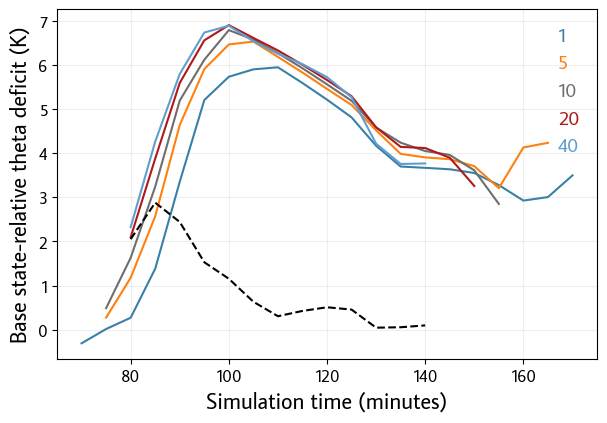

In [15]:
fig, ax = plt.subplots()

figure_name = "storm-ic_wk_surface_theta_by_rain_intensity"
figure_data = {}

storm_ds = storm_dss["ic_wk"].copy()
mean_deficits = {}
for rs_threshold_ix, rs_threshold in enumerate(blt.RS_TRACER_THRESHOLD_RAIN_RATES):
    mean_deficits[rs_threshold] = (
        storm_ds["theta_deficit"]
        .sel({"z": slice(0, 500)})
        .weighted(storm_ds["PCPRR"] >= rs_threshold)
        .mean(["x", "y", "z"])
    )
    blt.plot_and_save(
        figure_data,
        f"storm-ic_wk_rain-{int(blt.RS_TRACER_THRESHOLDS_MM_HR[rs_threshold_ix])}mmhr_theta_deficit",
        ax.plot,
        storm_ds["t_minutes"].values,
        mean_deficits[rs_threshold].values,
        color=cm.plotting.get_nth_color(rs_threshold_ix),
        label=blt.RS_TRACER_THRESHOLDS_MM_HR[rs_threshold_ix],
    )

diff = (
    mean_deficits[blt.RS_TRACER_THRESHOLD_RAIN_RATES[-1]]
    - mean_deficits[blt.RS_TRACER_THRESHOLD_RAIN_RATES[0]]
)
blt.plot_and_save(
    figure_data,
    f"storm-ic_wk_1mmhr_40mmhr_difference_theta_deficit",
    ax.plot,
    storm_ds["t_minutes"].values,
    diff.values,
    color="black",
    linestyle="dashed",
)

display(diff.to_pandas())

cm.plotting.clean_legend(ax)
ax.set_xlabel("Simulation time (minutes)")
ax.set_ylabel("Base state-relative theta deficit (K)")
blt.save_figure_data(figure_data, figure_name)

## Tracer entrainment

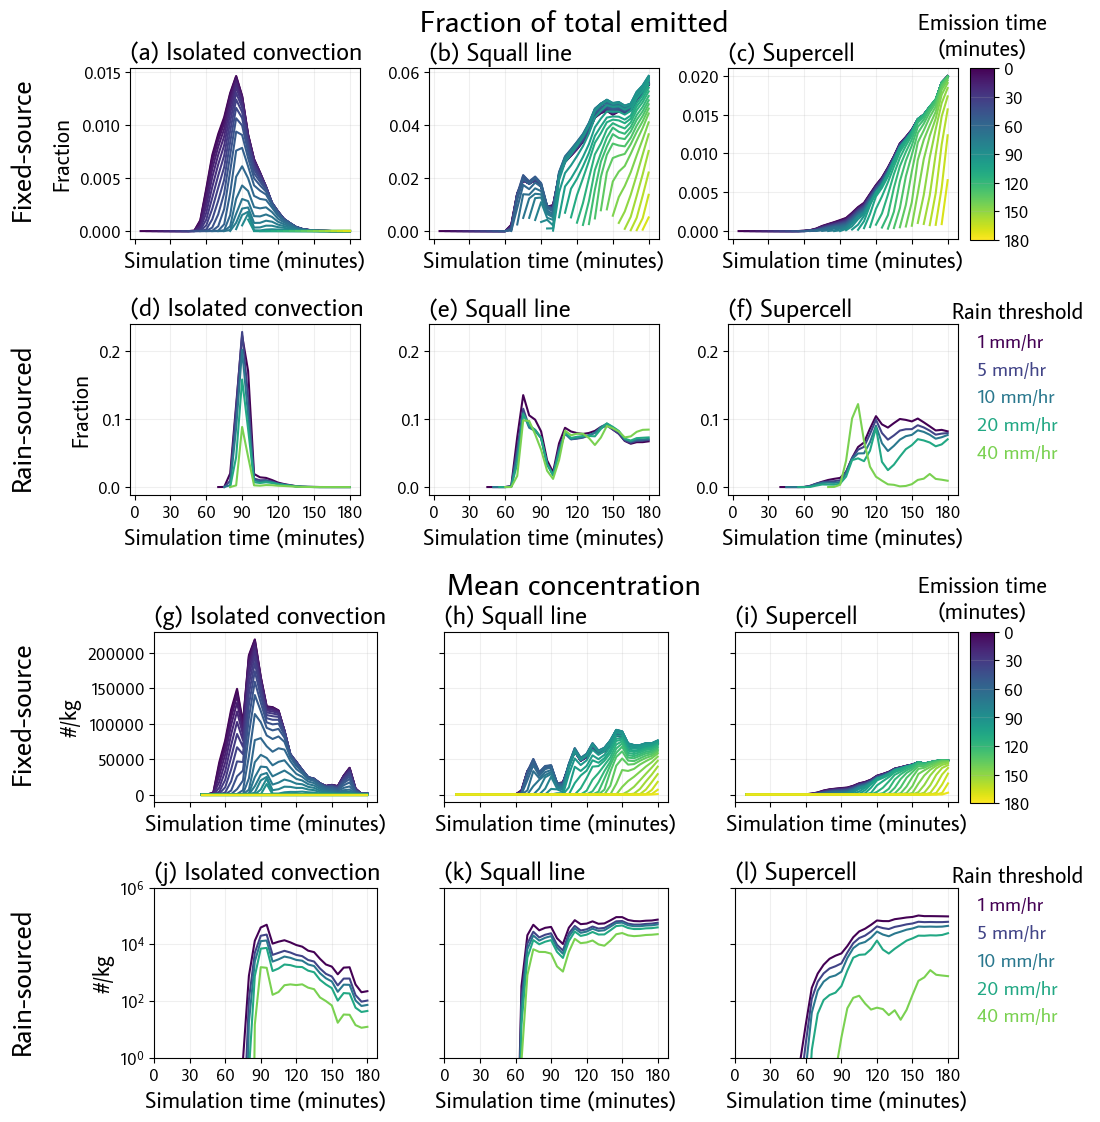

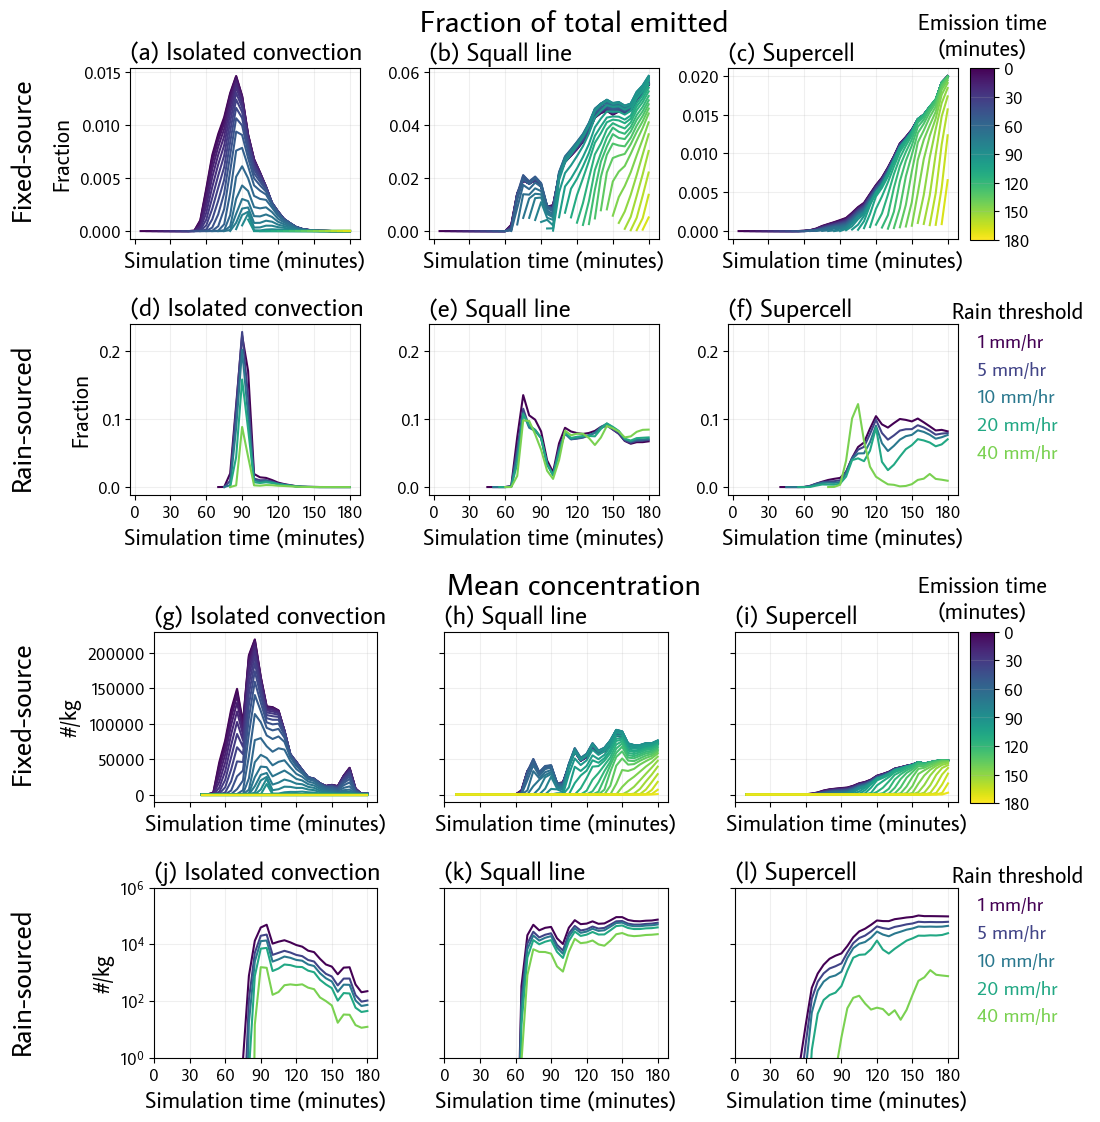

In [16]:
reload(cm.plotting)

figure_name = "f06_tracer_entrainment"
figure_data = {}

fig = plt.figure(figsize=(12, 11))
outer_subfigs = fig.subfigures(nrows=2, hspace=0.05)

########## Fractions ##########
axs = outer_subfigs[0].subplots(nrows=2, ncols=3, sharex=True)

# Space it better
outer_subfigs[0].subplots_adjust(left=0.13, hspace=0.5, top=0.87, right=0.82)


for tracer_type_ix, tracer_type in enumerate(["Fixed-source", "Rain-sourced"]):
    for storm_ix, (storm, this_tracer_ds) in enumerate(tracer_totals_dss.items()):

        ax = axs[tracer_type_ix, storm_ix]
        if tracer_type_ix == 0:
            for ix, tracer in enumerate(blt.FS_TRACERS):
                blt.plot_and_save(
                    figure_data,
                    f"storm-{storm}_tracer-{tracer}_frac_entrained_of_emitted",
                    ax.plot,
                    this_tracer_ds["t_minutes"],
                    this_tracer_ds[tracer + "_nc"]
                    / this_tracer_ds["ACC" + tracer + "_nc"],
                    color=mpl.colormaps[blt.PROGRESSIVE_CMAP](ix / len(blt.FS_TRACERS)),
                )
        else:
            # Rain-sourced
            for ix, tracer in enumerate(blt.RS_TRACERS):
                blt.plot_and_save(
                    figure_data,
                    f"storm-{storm}_tracer-{tracer}_frac_entrained_of_emitted",
                    ax.plot,
                    this_tracer_ds["t_minutes"],
                    (
                        this_tracer_ds[tracer + "_nc"]
                        / this_tracer_ds["ACC" + tracer + "_nc"]
                    ).values,
                    color=mpl.colormaps[blt.PROGRESSIVE_CMAP](ix / len(blt.RS_TRACERS)),
                    label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[ix]) + " mm/hr",
                )

        ax.set_title(
            blt.axes_title(storm_ix + tracer_type_ix * 3, blt.STORM_LABELS[storm])
        )
        if storm_ix == 0:
            ax.set_ylabel("Fraction")
        blt.label_x_axis(ax)

    # Add the row headers
    cm.plotting.add_row_header(
        axs[tracer_type_ix, 0],
        "Fixed-source" if tracer_type_ix == 0 else "Rain-sourced",
        xycoords="subfigure fraction",
        xy=(0.05, 0.72 - 0.5 * tracer_type_ix),
    )

    # Make the mean row share the y axis
    # x is already shared between all 6 in this subfigure so don't mess with it here
    cm.plotting.share_axes(axs[1], x=False, y=True)

outer_subfigs[0].suptitle("Fraction of total emitted", fontsize=22)


########## Means ##########
axs = outer_subfigs[1].subplots(nrows=2, ncols=3, sharex=True, sharey="row")

# Space it better
outer_subfigs[1].subplots_adjust(left=0.15, hspace=0.5, top=0.87, right=0.82)

for tracer_type_ix, tracer_type in enumerate(["Fixed-source", "Rain-sourced"]):
    for storm_ix, (storm, this_tracer_ds) in enumerate(tracer_totals_dss.items()):
        ax = axs[tracer_type_ix, storm_ix]
        if tracer_type_ix == 0:
            for ix, tracer in enumerate(sorted(blt.FS_TRACERS)):
                blt.plot_and_save(
                    figure_data,
                    f"storm-{storm}_tracer-{tracer}_nc",
                    ax.plot,
                    this_tracer_ds["t_minutes"],
                    this_tracer_ds[tracer + "_nc"] / this_tracer_ds["air_mass"],
                    color=mpl.colormaps[blt.PROGRESSIVE_CMAP](ix / len(blt.FS_TRACERS)),
                )
        else:
            # Rain-sourced
            for ix, tracer in enumerate(blt.RS_TRACERS):
                blt.plot_and_save(
                    figure_data,
                    f"storm-{storm}_tracer-{tracer}_nc",
                    ax.plot,
                    this_tracer_ds["t_minutes"],
                    (
                        this_tracer_ds[tracer + "_nc"] / this_tracer_ds["air_mass"]
                    ).values,
                    color=mpl.colormaps[blt.PROGRESSIVE_CMAP](ix / len(blt.RS_TRACERS)),
                    label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[ix]) + " mm/hr",
                )

        # Make these log scale
        if tracer_type_ix == 1:
            ax.set_yscale("log")
            ax.set_ylim([1e0, 1e6])
        ax.set_title(
            blt.axes_title(6 + storm_ix + tracer_type_ix * 3, blt.STORM_LABELS[storm])
        )
        if storm_ix == 0:
            ax.set_ylabel("#/kg")
        blt.label_x_axis(ax)

    # Add the row headers
    cm.plotting.add_row_header(
        axs[tracer_type_ix, 0],
        "Fixed-source" if tracer_type_ix == 0 else "Rain-sourced",
        xycoords="subfigure fraction",
        xy=(0.05, 0.72 - 0.5 * tracer_type_ix),
    )


outer_subfigs[1].suptitle("Mean concentration", fontsize=22)

# Add the colorbars
for subfig in outer_subfigs:
    # First do the fixed-source
    fs_cbar_ax = subfig.add_axes(
        [0.83, 0.55, 0.02, 0.32]
    )  # Left, bottom, width, height

    # Always set the vmin and vmax to 0 and 1
    fs_cbar = mpl.colorbar.ColorbarBase(
        ax=fs_cbar_ax,
        cmap=blt.PROGRESSIVE_CMAP + "_r",
        norm=mpl.colors.Normalize(vmin=0, vmax=1),
        orientation="vertical",
    )
    # Make the tick_values a linear range from 0 to 1 with the number of ticks you want
    tick_labels = np.arange(0, 181, 30)
    tick_values = (tick_labels / 180)[::-1]
    fs_cbar.set_ticks(tick_values)
    fs_cbar.set_ticklabels(tick_labels)
    fs_cbar_ax.xaxis.set_label_position("top")
    fs_cbar_ax.set_xlabel("Emission time\n(minutes)")
    fs_cbar_ax.get_xaxis().labelpad = 10

    # Now rain-sourced
    # Just make a legend here rather than a colorbar since it's only six values
    cm.plotting.clean_legend(
        subfig.axes[3],
        bbox_transform=subfig.transSubfigure,
        title="Rain threshold",
        bbox_to_anchor=[0.800, 0.468],  # x, y, width, height
        fontsize=14,
        title_fontsize=16,
        loc="upper left",
    )

blt.save_figure_data(figure_data, figure_name)
cm.plotting.fig_multisave(
    fig,
    figure_name,
    blt.FIGS_DIR,
    no_title_version=False,
)

## RS entrainment factors

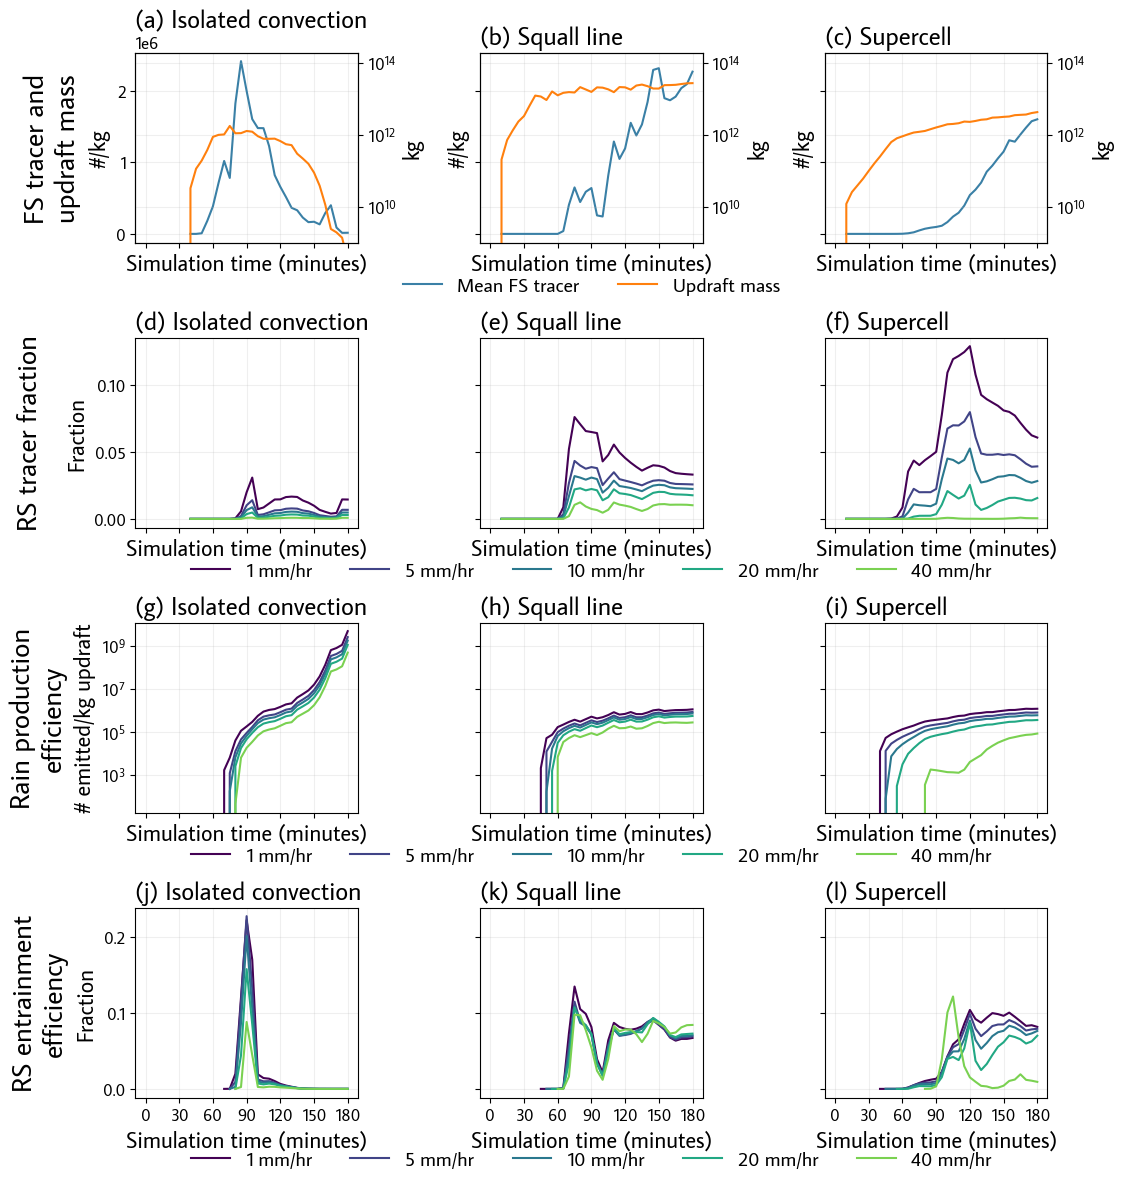

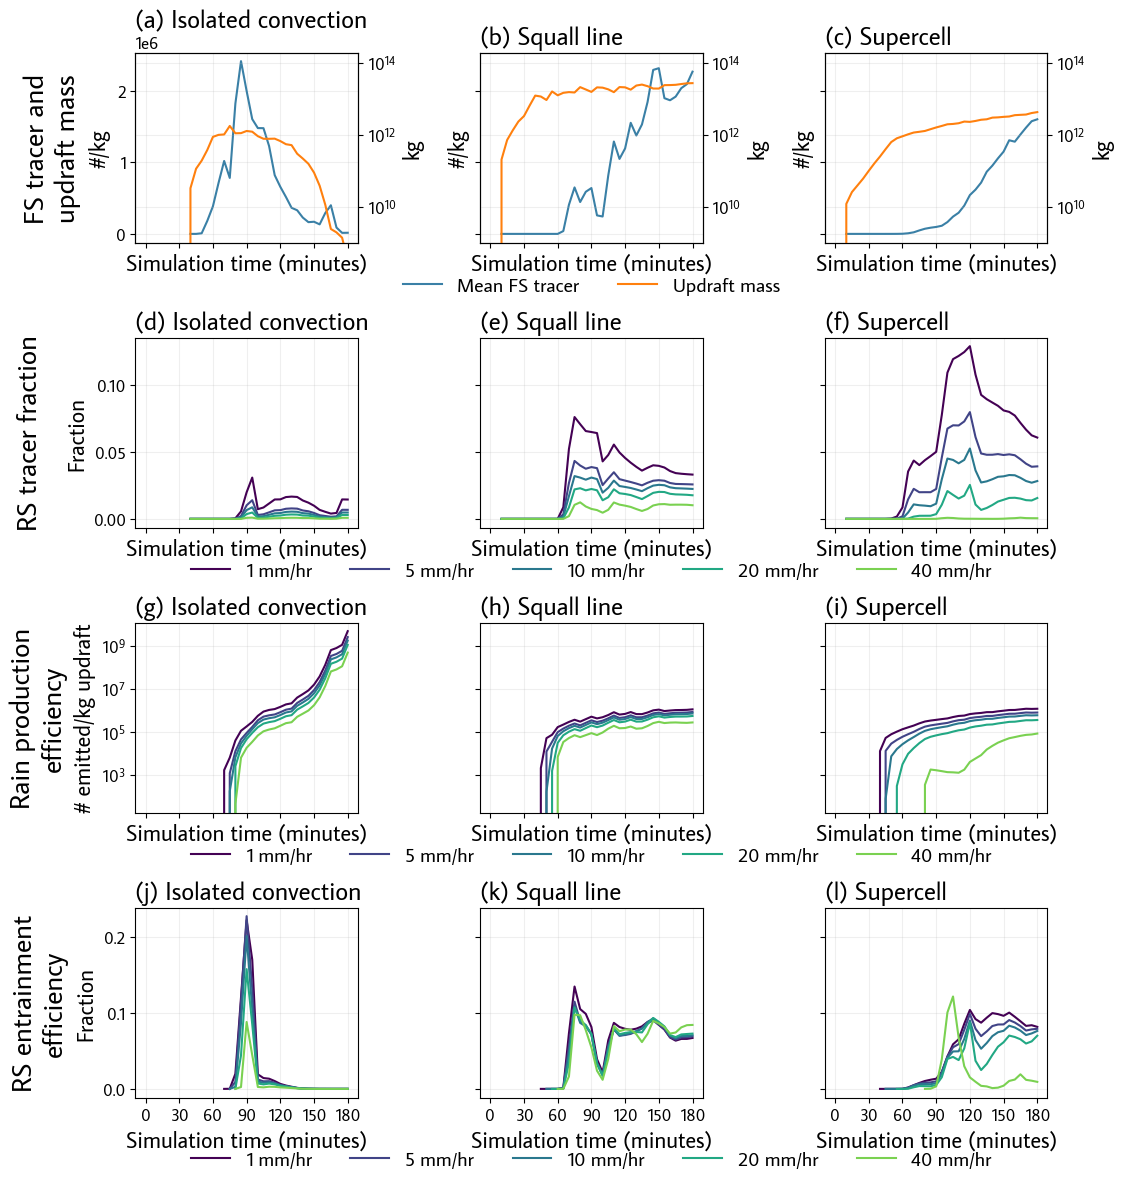

In [17]:
reload(cm.plotting)

from matplotlib.transforms import Bbox

figure_data = {}
figure_name = "f08_rs_entrainment_factors"

fig, axs = plt.subplots(nrows=4, ncols=3, figsize=(12, 11), sharex=True, sharey="row")
fig.subplots_adjust(wspace=0.55, left=0.19, hspace=0.5, bottom=0)

headers = []

bbox_to_anchor = (0.5, -0.23)


# Make functions for each row of this figure so that we can easily break them out into their own figures
def rs_factors_fs_entrainment(axs, ax_title_start_ix=0):
    updraft_axs = []
    for storm_ix, (storm, this_tracer_totals_ds) in enumerate(
        tracer_totals_dss.items()
    ):

        ax = axs[storm_ix]

        blt.plot_and_save(
            figure_data,
            f"storm-{storm}_fs_entrainment",
            ax.plot,
            this_tracer_totals_ds["t_minutes"],
            this_tracer_totals_ds["total_fs_tracer_nc"]
            / this_tracer_totals_ds["air_mass"],
            label="Mean FS tracer",
            color=cm.plotting.get_nth_color(0),
        )
        # Add an empty line to make the legend right
        ax.plot([], [], color=cm.plotting.get_nth_color(1), label="Updraft mass")
        updraft_ax = ax.twinx()
        updraft_axs.append(updraft_ax)
        blt.plot_and_save(
            figure_data,
            f"storm-{storm}_updraft_mass",
            updraft_ax.plot,
            this_tracer_totals_ds["t_minutes"],
            this_tracer_totals_ds["air_mass"],
            color=cm.plotting.get_nth_color(1),
        )
        updraft_ax.set_yscale("log")

        ax.set_title(
            blt.axes_title(ax_title_start_ix + storm_ix, blt.STORM_LABELS[storm])
        )

        ax.set_ylabel("#/kg")
        blt.label_x_axis(ax)
        updraft_ax.set_ylabel("kg")

    # Share the y axes of the updraft axes
    cm.plotting.share_axes(updraft_axs, x=False, y=True)
    # Set the ylim of them
    for ax in updraft_axs:
        ax.set_ylim([1e9, 2e14])

    axs[1].legend(loc="center", bbox_to_anchor=bbox_to_anchor, ncol=2)
    # cm.plotting.clean_legend(axs[0], loc="upper left")


def rs_factors_rs_fraction(axs, ax_title_start_ix=0):
    for storm_ix, (storm, this_tracer_totals_ds) in enumerate(
        tracer_totals_dss.items()
    ):
        # Second row: RS tracer fraction
        ax = axs[storm_ix]
        for tracer_ix, tracer in enumerate(blt.RS_TRACERS):
            blt.plot_and_save(
                figure_data,
                f"storm-{storm}_rs_fraction",
                ax.plot,
                this_tracer_totals_ds["t_minutes"],
                this_tracer_totals_ds[tracer + "_nc"]
                / this_tracer_totals_ds["total_fs_tracer_nc"],
                label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[tracer_ix]) + " mm/hr",
                color=mpl.colormaps[blt.PROGRESSIVE_CMAP](
                    tracer_ix / len(blt.RS_TRACERS)
                ),
            )
        ax.set_title(
            blt.axes_title(ax_title_start_ix + storm_ix, blt.STORM_LABELS[storm])
        )
        if storm_ix == 0:
            ax.set_ylabel("Fraction")
        blt.label_x_axis(ax)

        # if storm_ix == 0:
        #     cm.plotting.clean_legend(ax, loc="upper left")
    axs[1].legend(loc="center", bbox_to_anchor=bbox_to_anchor, ncol=5)


def rs_factors_rain_efficiency(
    axs, ax_title_start_ix=0, storms=tracer_totals_dss.keys()
):
    for storm_ix, storm in enumerate(storms):
        this_tracer_totals_ds = tracer_totals_dss[storm]
        # for storm_ix, (storm, this_tracer_totals_ds) in enumerate(tracer_totals_dss.items()):
        # Third row: Rain production efficiency
        ax = axs[storm_ix]
        for tracer_ix, tracer in enumerate(blt.RS_TRACERS):
            blt.plot_and_save(
                figure_data,
                f"storm-{storm}_rain_efficiency",
                ax.plot,
                this_tracer_totals_ds["t_minutes"],
                this_tracer_totals_ds["ACC" + tracer + "_nc"]
                / this_tracer_totals_ds["air_mass"],
                label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[tracer_ix]) + " mm/hr",
                color=mpl.colormaps[blt.PROGRESSIVE_CMAP](
                    tracer_ix / len(blt.RS_TRACERS)
                ),
            )
            ax.set_title(
                blt.axes_title(ax_title_start_ix + storm_ix, blt.STORM_LABELS[storm])
            )
            if storm_ix == 0:
                ax.set_ylabel("# emitted/kg updraft")
        ax.set_yscale("log")
        blt.label_x_axis(ax)

        # if storm_ix == 0:
        #     cm.plotting.clean_legend(ax, loc="upper left")
    axs[1].legend(loc="center", bbox_to_anchor=bbox_to_anchor, ncol=5)


def rs_factors_rs_entrainment_efficiency(axs, ax_title_start_ix=0):
    for storm_ix, (storm, this_tracer_totals_ds) in enumerate(
        tracer_totals_dss.items()
    ):
        ax = axs[storm_ix]
        for tracer_ix, tracer in enumerate(blt.RS_TRACERS):
            blt.plot_and_save(
                figure_data,
                f"storm-{storm}_rs_entrainment_efficiency",
                ax.plot,
                this_tracer_totals_ds["t_minutes"],
                this_tracer_totals_ds[tracer + "_nc"]
                / this_tracer_totals_ds["ACC" + tracer + "_nc"],
                label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[tracer_ix]) + " mm/hr",
                color=mpl.colormaps[blt.PROGRESSIVE_CMAP](
                    tracer_ix / len(blt.RS_TRACERS)
                ),
            )
            ax.set_title(blt.axes_title(9 + storm_ix, blt.STORM_LABELS[storm]))
            if storm_ix == 0:
                ax.set_ylabel("Fraction")
            blt.label_x_axis(ax)
    # cm.plotting.clean_legend(axs[0], loc="upper left")
    axs[1].legend(
        loc="center",
        bbox_to_anchor=(bbox_to_anchor[0], bbox_to_anchor[1] - 0.1),
        ncol=5,
    )


# Create the figure
rs_factors_fs_entrainment(axs[0], ax_title_start_ix=0)
rs_factors_rs_fraction(axs[1], ax_title_start_ix=3)
rs_factors_rain_efficiency(axs[2], ax_title_start_ix=6)
rs_factors_rs_entrainment_efficiency(axs[3], ax_title_start_ix=9)


header_pad = 22
headers.append(
    cm.plotting.add_row_header(
        axs[0][0],
        "FS tracer and\nupdraft mass",
        pad=header_pad,
        # xycoords="subfigure fraction",
        # xy=(0.05, 0.87),
    )
)

headers.append(
    cm.plotting.add_row_header(
        axs[1][0],
        "RS tracer fraction",
        pad=header_pad,
        # "In-updraft RS tracer /\nin-updraft FS tracer",
        # xycoords="subfigure fraction",
        # xy=(0.05, 0.63),
    )
)

headers.append(
    cm.plotting.add_row_header(
        axs[2][0],
        # "RS tracer emitted /\nupdraft mass",
        "Rain production\nefficiency",
        pad=header_pad,
        # xycoords="subfigure fraction",
        # xy=(0.05, 0.38),
    )
)

headers.append(
    cm.plotting.add_row_header(
        axs[3][0],
        "RS entrainment\nefficiency",
        pad=header_pad,
        # xycoords="subfigure fraction",
        # xy=(0.05, 0.14),
    )
)

blt.save_figure_data(figure_data, figure_name)
cm.plotting.fig_multisave(fig, figure_name, blt.FIGS_DIR)

# Tracer entrainment statistics

In [18]:
# Set the number of decimal places in the pandas display
# pd.options.display.float_format = "{:,.3f}".format
# pd.set_option('display.precision', 3)

tracer_stats = {}

tracer_stats_tracers = blt.RS_TRACERS + ["total_fs_tracer"]

for storm_ix, (storm, this_tracer_ds) in enumerate(tracer_totals_dss.items()):
    # Limit to only when there's an updraft
    this_tracer_ds = this_tracer_ds.where(this_tracer_ds["air_mass"] > 0)
    this_storm_stats = {}
    # print(f'{blt.STORM_LABELS[storm]}:')
    for ix, tracer in enumerate(tracer_stats_tracers):
        this_tracer_stats = {}
        this_tracer_stats["mean_mean"] = (
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["air_mass"])
            .mean(...)
            .values
        )
        this_tracer_stats["max_mean"] = (
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["air_mass"])
            .max(...)
            .values
        )
        this_tracer_stats["max_mean_time"] = this_tracer_ds["t_minutes"].values[
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["air_mass"])
            .argmax("time")
            .values
        ]
        this_tracer_stats["eos_mean"] = (
            this_tracer_ds.isel({"time": -1})[tracer + "_nc"]
            / this_tracer_ds["air_mass"].isel({"time": -1})
        ).values
        this_post_100_ds = this_tracer_ds.isel({"time": slice(20, 37)})
        this_tracer_stats["max_mean_post_t100"] = (
            (this_post_100_ds[tracer + "_nc"] / this_post_100_ds["air_mass"])
            .max(...)
            .values
        )
        this_tracer_stats["min_mean_post_t100"] = (
            (this_post_100_ds[tracer + "_nc"] / this_post_100_ds["air_mass"])
            .min(...)
            .values
        )
        this_tracer_stats["mean_tracer_fraction"] = (
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["total_fs_tracer_nc"])
            .mean()
            .values
        )
        this_tracer_stats["max_tracer_fraction"] = (
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["total_fs_tracer_nc"])
            .max()
            .values
        )
        this_tracer_stats["mean_rain_production_efficiency"] = (
            (this_tracer_ds["ACC" + tracer + "_nc"] / this_tracer_ds["air_mass"])
            .mean()
            .values
        )
        this_tracer_stats["max_rain_production_efficiency"] = (
            (this_tracer_ds["ACC" + tracer + "_nc"] / this_tracer_ds["air_mass"])
            .max()
            .values
        )
        this_tracer_stats["eos_rain_production_efficiency"] = (
            (this_tracer_ds["ACC" + tracer + "_nc"] / this_tracer_ds["air_mass"])
            .isel({"time": -1})
            .values
        )
        this_tracer_stats["integrated_rain_production_efficiency"] = (
            (this_tracer_ds["ACC" + tracer + "_nc"] / this_tracer_ds["air_mass"])
            .sum()
            .values
        )
        this_tracer_stats["t90_rain_production_efficiency"] = (
            (this_tracer_ds["ACC" + tracer + "_nc"] / this_tracer_ds["air_mass"])
            .isel({"time": 90 // 5})
            .values
        )
        this_tracer_stats["t100_rain_production_efficiency"] = (
            (this_tracer_ds["ACC" + tracer + "_nc"] / this_tracer_ds["air_mass"])
            .isel({"time": 100 // 5})
            .values
        )
        this_tracer_stats["t100_rain_production_efficiency"] = (
            (this_tracer_ds["ACC" + tracer + "_nc"] / this_tracer_ds["air_mass"])
            .isel({"time": 100 // 5})
            .values
        )
        this_tracer_stats["t180_over_t75_rain_production_efficiency"] = (
            (this_tracer_ds["ACC" + tracer + "_nc"] / this_tracer_ds["air_mass"]).isel(
                {"time": 180 // 5}
            )
            / (
                this_tracer_ds["ACC" + tracer + "_nc"] / this_tracer_ds["air_mass"]
            ).isel({"time": 75 // 5})
        ).values
        this_tracer_stats["t180_over_t75_updraft_mass"] = (
            (this_tracer_ds["air_mass"]).isel({"time": 180 // 5})
            / (this_tracer_ds["air_mass"]).isel({"time": 75 // 5})
        ).values
        this_tracer_stats["max_entrainment_efficiency"] = (
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["ACC" + tracer + "_nc"])
            .max()
            .values
        )
        this_tracer_stats["max_entrainment_efficiency_time"] = this_tracer_ds[
            "t_minutes"
        ].values[
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["ACC" + tracer + "_nc"])
            .argmax("time")
            .values
        ]
        this_tracer_stats["mean_entrainment_efficiency"] = (
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["ACC" + tracer + "_nc"])
            .mean()
            .values
        )
        this_tracer_stats["integrated_entrainment_efficiency"] = (
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["ACC" + tracer + "_nc"])
            .sum()
            .values
        )
        this_tracer_stats["eos_entrainment_efficiency"] = (
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["ACC" + tracer + "_nc"])
            .isel({"time": -1})
            .values
        )
        this_tracer_stats["t120_to_t180_mean_entrainment_efficiency"] = (
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["ACC" + tracer + "_nc"])
            .isel({"time": slice(24, 37)})
            .mean()
            .values
        )
        this_tracer_stats["t85_to_t180_mean_entrainment_efficiency"] = (
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["ACC" + tracer + "_nc"])
            .isel({"time": slice(17, 37)})
            .mean()
            .values
        )

        this_storm_stats[tracer] = this_tracer_stats
    tracer_stats[storm] = this_storm_stats

for k, v in tracer_stats.items():
    display(HTML(f"<h2>{blt.STORM_LABELS[k]}</h2>"))
    display(pd.DataFrame(v))

blt.save_figure_data(tracer_stats, "entrainment_factor_stats")

# Also display each of them relative to the others
for comparison_pair in [
    ["sl_wk", "ic_wk"],
    ["ic_wk", "sl_wk"],
    ["sc_wk", "ic_wk"],
    ["ic_wk", "sc_wk"],
    ["sl_wk", "sc_wk"],
    ["sc_wk", "sl_wk"],
]:
    display(
        HTML(
            f"<h2>{blt.STORM_LABELS[comparison_pair[0]]} / {blt.STORM_LABELS[comparison_pair[1]]}</h2>"
        )
    )
    display(
        pd.DataFrame(tracer_stats[comparison_pair[0]])
        / pd.DataFrame(tracer_stats[comparison_pair[1]])
    )

,TRACERP001,TRACERP002,TRACERP003,TRACERP004,TRACERP005,total_fs_tracer
mean_mean,6663.009345275112,2996.7079207732086,1885.2776446222708,1011.1618522042997,208.2492610167458,664440.586616327
max_mean,49337.569551056935,22294.02564588522,13806.66680082209,7582.236253100051,1589.7290694796964,2409430.770490555
max_mean_time,95.0,95.0,95.0,95.0,90.0,85.0
eos_mean,227.65806851095957,106.55195247399685,74.87060872457329,45.950401649463956,12.70235164974087,15761.939131538822
max_mean_post_t100,14071.735238831488,5977.941513976809,3759.3639992886697,1974.240754010879,396.3894040764422,1475798.8714067077
min_mean_post_t100,209.14826282565906,97.69149860421071,68.72116063261079,42.249903480749644,11.778659430892882,14405.285592975932
mean_tracer_fraction,0.008521414250234005,0.003849415872519754,0.002527656151991415,0.0014319926010350644,0.0003293079019694075,1.0
max_tracer_fraction,0.03081499982321125,0.013924285338492177,0.008623295368982258,0.004735673259239797,0.0009441018415200228,1.0
mean_rain_production_efficiency,265582093.60609365,140325968.8491804,97224316.78977661,60839614.79492205,26670135.678800937,103107112384.9699
max_rain_production_efficiency,4907193843.160071,2588678864.9909644,1792873175.4469476,1121660856.5618403,491622858.68353873,1935342517757.7158


,TRACERP001,TRACERP002,TRACERP003,TRACERP004,TRACERP005,total_fs_tracer
mean_mean,36242.65927917738,24873.530082766643,20980.162121490586,16114.182787398908,8349.393547718271,872788.1329092989
max_mean,91444.96619322198,66699.75021651771,58724.607660769456,46601.10182271892,25208.84586177956,2311308.727402119
max_mean_time,145.0,150.0,150.0,150.0,150.0,150.0
eos_mean,74765.67985132641,58167.768913717395,50548.6115534272,39853.40683887323,23036.122165624794,2262908.9722744985
max_mean_post_t100,91444.96619322198,66699.75021651771,58724.607660769456,46601.10182271892,25208.84586177956,2311308.727402119
min_mean_post_t100,10390.892362497374,6104.588270649039,4739.558113273723,3364.9041929232303,1114.647778968347,242337.5075648689
mean_tracer_fraction,0.031006144281676962,0.01992190060760361,0.016242614096991383,0.012131901115064672,0.0058907694516230095,1.0
max_tracer_fraction,0.07596028739555641,0.0432221543505255,0.03192378882728203,0.022857817496823436,0.012331471252720591,1.0
mean_rain_production_efficiency,491500.24286277156,350903.16832297284,291314.1247545099,220992.29680192735,113198.75320530216,55675102.6745983
max_rain_production_efficiency,1114264.392740796,841103.0762814732,715065.5452129811,547145.7272310334,292224.0791109083,353959486.292607


,TRACERP001,TRACERP002,TRACERP003,TRACERP004,TRACERP005,total_fs_tracer
mean_mean,37022.12516932866,21938.881706123244,14366.889344481364,6341.7395192252525,166.68738099457642,459121.1035008848
max_mean,104209.54549858188,62891.170732920014,45117.58295756119,24886.965386409724,1249.062165245225,1598534.3333260072
max_mean_time,155.0,155.0,180.0,180.0,165.0,180.0
eos_mean,96960.28460642057,62610.94128346499,45117.58295756119,24886.965386409724,768.5860791882975,1598534.3333260072
max_mean_post_t100,104209.54549858188,62891.170732920014,45117.58295756119,24886.965386409724,1249.062165245225,1598534.3333260072
min_mean_post_t100,17963.29381814655,11089.033357974626,7410.578384414412,3418.995586103446,22.529598888116887,164667.83828953392
mean_tracer_fraction,0.054573206334736245,0.03105178002588213,0.019327702773106664,0.007782637829319258,0.00018216937416488916,1.0
max_tracer_fraction,0.1288298728085018,0.07965072679243063,0.052501978095467895,0.025348305654585124,0.0009009595225038643,1.0
mean_rain_production_efficiency,480062.8412074046,309212.87097314023,222502.5745728981,119284.57486164472,15402.894522277862,271687429.85176945
max_rain_production_efficiency,1188077.1081964436,794052.4853246894,590668.6307169868,355011.04706154246,82990.13347327344,1742404926.9531972


,TRACERP001,TRACERP002,TRACERP003,TRACERP004,TRACERP005,total_fs_tracer
mean_mean,5.439383,8.300285,11.12842,15.936304,40.093269,1.313568
max_mean,1.853455,2.991822,4.253352,6.146089,15.857322,0.959276
max_mean_time,1.526316,1.578947,1.578947,1.578947,1.666667,1.764706
eos_mean,328.412168,545.90993,675.146261,867.313569,1813.532077,143.56793
max_mean_post_t100,6.498485,11.157645,15.620889,23.604569,63.596165,1.566141
min_mean_post_t100,49.681944,62.488429,68.967958,79.642885,94.632822,16.822819
mean_tracer_fraction,3.638615,5.175305,6.425959,8.472042,17.888333,1.0
max_tracer_fraction,2.465043,3.104084,3.702041,4.82673,13.06159,1.0
mean_rain_production_efficiency,0.001851,0.002501,0.002996,0.003632,0.004244,0.00054
max_rain_production_efficiency,0.000227,0.000325,0.000399,0.000488,0.000594,0.000183


,TRACERP001,TRACERP002,TRACERP003,TRACERP004,TRACERP005,total_fs_tracer
mean_mean,0.183844,0.120478,0.08986,0.06275,0.024942,0.761285
max_mean,0.539533,0.334245,0.235109,0.162705,0.063062,1.042453
max_mean_time,0.655172,0.633333,0.633333,0.633333,0.6,0.566667
eos_mean,0.003045,0.001832,0.001481,0.001153,0.000551,0.006965
max_mean_post_t100,0.153882,0.089625,0.064017,0.042365,0.015724,0.638512
min_mean_post_t100,0.020128,0.016003,0.014499,0.012556,0.010567,0.059443
mean_tracer_fraction,0.27483,0.193225,0.155619,0.118035,0.055902,1.0
max_tracer_fraction,0.405673,0.322156,0.270121,0.20718,0.07656,1.0
mean_rain_production_efficiency,540.349873,399.899407,333.743916,275.301971,235.6045,1851.942923
max_rain_production_efficiency,4403.976179,3077.718936,2507.285084,2050.022144,1682.348902,5467.695012


,TRACERP001,TRACERP002,TRACERP003,TRACERP004,TRACERP005,total_fs_tracer
mean_mean,5.556367,7.320994,7.62057,6.271735,0.800422,0.690989
max_mean,2.112174,2.820988,3.267811,3.282272,0.785708,0.663449
max_mean_time,1.631579,1.631579,1.894737,1.894737,1.833333,2.117647
eos_mean,425.903133,587.609517,602.607401,541.604959,60.507385,101.417365
max_mean_post_t100,7.405593,10.52054,12.001387,12.605841,3.151099,1.083165
min_mean_post_t100,85.887846,113.51073,107.835466,80.923157,1.912747,11.431071
mean_tracer_fraction,6.404243,8.066621,7.646492,5.434831,0.553189,1.0
max_tracer_fraction,4.180752,5.720274,6.088389,5.35263,0.954303,1.0
mean_rain_production_efficiency,0.001808,0.002204,0.002289,0.001961,0.000578,0.002635
max_rain_production_efficiency,0.000242,0.000307,0.000329,0.000317,0.000169,0.0009


,TRACERP001,TRACERP002,TRACERP003,TRACERP004,TRACERP005,total_fs_tracer
mean_mean,0.179974,0.136593,0.131224,0.159446,1.24934,1.447201
max_mean,0.473446,0.354486,0.306015,0.304667,1.272738,1.507275
max_mean_time,0.612903,0.612903,0.527778,0.527778,0.545455,0.472222
eos_mean,0.002348,0.001702,0.001659,0.001846,0.016527,0.00986
max_mean_post_t100,0.135033,0.095052,0.083324,0.079328,0.31735,0.92322
min_mean_post_t100,0.011643,0.00881,0.009273,0.012357,0.522808,0.087481
mean_tracer_fraction,0.156146,0.123968,0.130779,0.183998,1.807702,1.0
max_tracer_fraction,0.239191,0.174817,0.164247,0.186824,1.047885,1.0
mean_rain_production_efficiency,553.223601,453.816713,436.958165,510.037571,1731.501546,379.506378
max_rain_production_efficiency,4130.366463,3260.085338,3035.32824,3159.509728,5923.871165,1110.730627


,TRACERP001,TRACERP002,TRACERP003,TRACERP004,TRACERP005,total_fs_tracer
mean_mean,0.978946,1.133765,1.460313,2.540972,50.090136,1.900998
max_mean,0.87751,1.060558,1.30159,1.87251,20.182219,1.445892
max_mean_time,0.935484,0.967742,0.833333,0.833333,0.909091,0.833333
eos_mean,0.771096,0.929035,1.120375,1.601377,29.972078,1.415615
max_mean_post_t100,0.87751,1.060558,1.30159,1.87251,20.182219,1.445892
min_mean_post_t100,0.578451,0.550507,0.639567,0.984179,49.474817,1.471675
mean_tracer_fraction,0.568157,0.64157,0.84038,1.558842,32.336772,1.0
max_tracer_fraction,0.589617,0.542646,0.608049,0.901749,13.687042,1.0
mean_rain_production_efficiency,1.023825,1.134827,1.309262,1.852648,7.349187,0.204923
max_rain_production_efficiency,0.937872,1.059254,1.210604,1.541208,3.521191,0.203144


,TRACERP001,TRACERP002,TRACERP003,TRACERP004,TRACERP005,total_fs_tracer
mean_mean,1.021507,0.882017,0.684784,0.39355,0.019964,0.52604
max_mean,1.139588,0.9429,0.768291,0.534042,0.049549,0.691614
max_mean_time,1.068966,1.033333,1.2,1.2,1.1,1.2
eos_mean,1.296856,1.076385,0.892558,0.624463,0.033364,0.706407
max_mean_post_t100,1.139588,0.9429,0.768291,0.534042,0.049549,0.691614
min_mean_post_t100,1.728754,1.816508,1.563559,1.016075,0.020212,0.679498
mean_tracer_fraction,1.760077,1.558676,1.189938,0.641502,0.030925,1.0
max_tracer_fraction,1.696016,1.842822,1.644604,1.108956,0.073062,1.0
mean_rain_production_efficiency,0.97673,0.881191,0.763789,0.539768,0.136069,4.879873
max_rain_production_efficiency,1.066243,0.944061,0.826034,0.648842,0.283995,4.922611


## IC rain production efficiency comparison

In [19]:
# Do this one custom bc we want to compare the t=100 IC rain production efficiency with the end of simulation/max
# values from the other two storms

# IC t=100 rain production efficiency
rpe_comparison_dss = {}
for storm in ["ic_wk", "sl_wk", "sc_wk"]:
    rpe_comparison_dss[storm] = tracer_totals_dss[storm].where(
        tracer_totals_dss[storm] > 0
    )

rpe_comparison_vals = {"ic_wk": {}, "sl_wk": {}, "sc_wk": {}}
for ix, tracer in enumerate(tracer_stats_tracers):
    rpe_comparison_vals["ic_wk"][tracer] = (
        (
            rpe_comparison_dss["ic_wk"]["ACC" + tracer + "_nc"]
            / rpe_comparison_dss["ic_wk"]["air_mass"]
        )
        .sel({"time": blt.minutes_to_simulation_time(100)})
        .values
    )
    for storm in ["sl_wk", "sc_wk"]:
        rpe_comparison_vals[storm][tracer] = (
            (
                rpe_comparison_dss[storm]["ACC" + tracer + "_nc"]
                / rpe_comparison_dss[storm]["air_mass"]
            )
            .isel({"time": -1})
            .values
        )

comparison_vals = pd.DataFrame.from_dict(rpe_comparison_vals)
for storm in ["sl_wk", "sc_wk"]:
    print(storm)
    display(comparison_vals["ic_wk"] / comparison_vals[storm])

sl_wk


TRACERP001         0.500229
TRACERP002         0.410785
TRACERP003         0.356481
TRACERP004         0.299209
TRACERP005         0.247392
total_fs_tracer    7.755481
dtype: object

sc_wk


TRACERP001         0.469894
TRACERP002         0.437077
TRACERP003         0.431557
TRACERP004         0.461143
TRACERP005         0.814705
total_fs_tracer    4.230474
dtype: object

# Updraft and tracer vertical profile

0it [00:00, ?it/s]

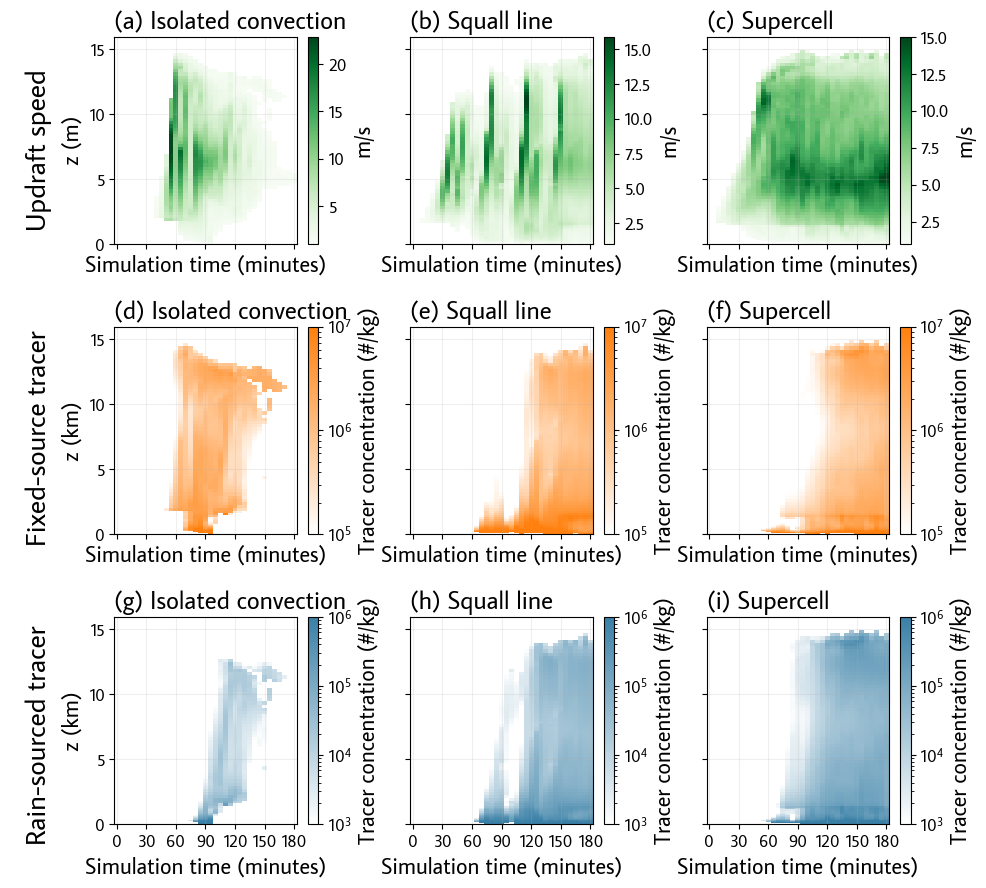

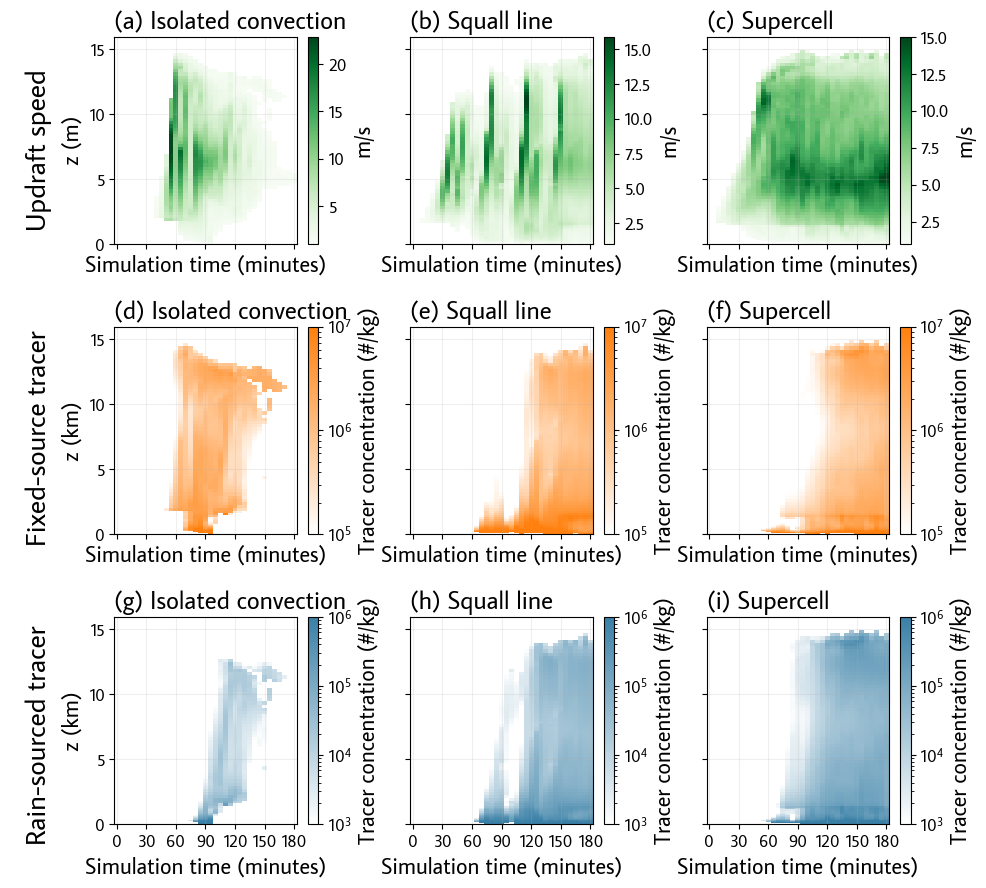

In [20]:
# Need to run the cell above first
# Do the plotting

figure_name = "f07_tracer_profiles_vs_time"
figure_data = {}

reload(cm.plotting)

# Calculate the updraft speed profiles

updraft_speed_profiles = {}

# Mean updraft speed
for storm_ix, (storm, storm_ds) in tqdm(enumerate(storm_dss.items())):
    storm_ds = storm_ds.where(storm_ds["in_analysis"] & storm_ds["in_updraft"]).sel(
        {"z": slice(0, 16000)}
    )
    updraft_speed_profiles[storm] = (
        storm_ds["WC"].mean(["x", "y"], skipna=True).compute()
    )

fig, axs = plt.subplots(figsize=(10, 9), nrows=3, ncols=3, sharex=True, sharey=True)
fig.subplots_adjust(left=0.13, hspace=0.4)

# Updraft speeds
for storm_ix, (storm, this_storm_ds) in enumerate(storm_dss.items()):
    ax = axs[0, storm_ix]
    updraft_artist = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_max_updraft_speed",
        ax.pcolormesh,
        updraft_speed_profiles[storm]["t_minutes"].values,
        updraft_speed_profiles[storm]["z"].values,
        updraft_speed_profiles[storm].values.transpose(),
        cmap="Greens",
    )
    cbar = fig.colorbar(updraft_artist, ax=ax)
    cbar.ax.set_ylabel("m/s")
    ax.set_title(blt.axes_title(storm_ix, blt.STORM_LABELS[storm]))
    blt.label_x_axis(ax)

cm.plotting.add_row_header(
    axs[0, 0], "Updraft speed", xycoords="figure fraction", xy=(0.05, 0.82)
)
axs[0, 0].set_ylabel("z (m)")

cmap_limits = {
    0: {"ic_wk": [1e5, 1e7], "sl_wk": [1e5, 1e7], "sc_wk": [1e5, 1e7]},
    1: {"ic_wk": [1e3, 1e6], "sl_wk": [1e3, 1e6], "sc_wk": [1e3, 1e6]},
}

# Tracers
for tracer_type_ix, tracer_type in enumerate(["Fixed-source", "Rain-sourced"]):
    for storm_ix, (storm, this_tracer_ds) in enumerate(
        tracer_totals_profile_dss.items()
    ):
        this_tracer_ds = this_tracer_ds.sel({"z": slice(0, 16000)})
        ax = axs[tracer_type_ix + 1, storm_ix]
        cbar = plt.colorbar(
            blt.plot_and_save(
                figure_data,
                f"storm-{storm}_tracertype-{['fs', 'rs'][tracer_type_ix]}_nc_profile",
                ax.pcolormesh,
                this_tracer_ds["t_minutes"].values,
                this_tracer_ds["z"].values,
                (
                    (
                        this_tracer_ds["total_fs_tracer_nc"]
                        if tracer_type_ix == 0
                        else this_tracer_ds[blt.RS_TRACERS[0] + "_nc"]
                    )
                    / this_tracer_ds["air_mass"]
                ).values.transpose(),
                norm=colors.LogNorm(
                    vmin=cmap_limits[tracer_type_ix][storm][0],
                    vmax=cmap_limits[tracer_type_ix][storm][1],
                ),
                # norm=(colors.LogNorm(vmin=1e4, vmax=1e8) if metric_ix == 0 else colors.LogNorm(vmin=1e4, vmax=1e6)),
                cmap=cm.plotting.single_color_cmap(
                    cm.plotting.get_nth_color(1 if tracer_type_ix == 0 else 0)
                ),
            )
        )
        cbar.ax.set_ylabel("Tracer concentration (#/kg)")

        ax.set_title(
            blt.axes_title(3 + tracer_type_ix * 3 + storm_ix, blt.STORM_LABELS[storm])
        )
        if storm_ix == 0:
            ax.set_ylabel("z (km)")
        blt.label_x_axis(ax)
        cm.plotting.scale_axes_ticks(ax=ax, y=True, x=False, scale=1000)

    cm.plotting.add_row_header(
        axs[tracer_type_ix, 0],
        tracer_type + " tracer",
        xycoords="figure fraction",
        xy=(0.05, 0.5 - 0.33 * tracer_type_ix),
    )

blt.save_figure_data(figure_data, figure_name)
cm.plotting.fig_multisave(fig, figure_name, blt.FIGS_DIR)

# Presentation figures

In [10]:
PRESENTATION_FIGS_DIR = Path("/home/cmdavis4/projects/tracer_paper/presentation_figures")

## Tracer entrainment, column

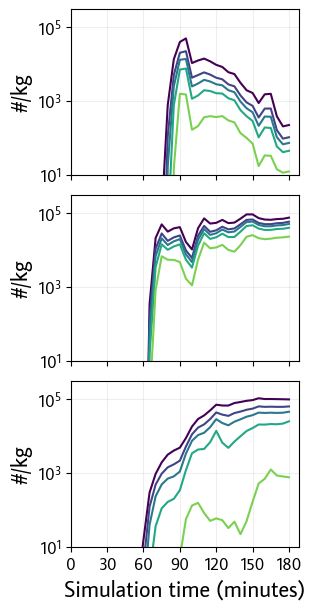

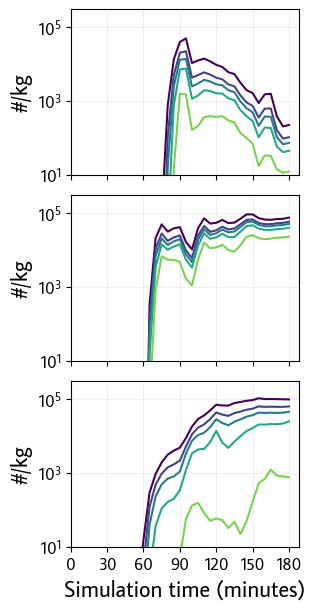

In [45]:
reload(cm.plotting)
fig, tracer_entrainment_axs = plt.subplots(figsize=(3, 6), nrows=3, ncols=1, layout='constrained', squeeze=True, sharey=True, sharex=True)
figure_name = f"rs_tracer_entrainment_column"

for storm_ix, (storm, this_tracer_ds) in enumerate(tracer_totals_dss.items()):
    ax = tracer_entrainment_axs[storm_ix]
    # Rain-sourced
    for ix, tracer in enumerate(blt.RS_TRACERS):
        ax.plot(
            this_tracer_ds["t_minutes"],
            (
                this_tracer_ds[tracer + "_nc"] / this_tracer_ds["air_mass"]
            ).values,
            color=mpl.colormaps[blt.PROGRESSIVE_CMAP](ix / len(blt.RS_TRACERS)),
            label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[ix]) + " mm/hr")
    if storm_ix == 2:
        blt.label_x_axis(ax)
    ax.set_ylabel("#/kg")
    ax.set_yscale('log')
    ax.set_ylim([1e1, 3e5])

cm.plotting.fig_multisave(
    fig,
    figure_name,
    PRESENTATION_FIGS_DIR,
    no_title_version=False,
    extensions=['.png']
)

## Tracer entrainment, panels

### Highlight low

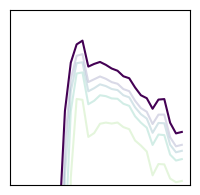

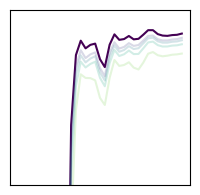

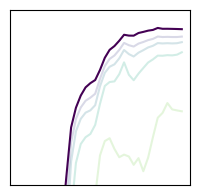

In [52]:
reload(cm.plotting)
# fig, axs = plt.subplots(figsize=(3, 6), nrows=3, ncols=1, layout='constrained', squeeze=True, sharey=True, sharex=True)
figure_name = f"rs_tracer_entrainment_panel_highlight-low"

rs_highlight_ixs = [0]

highlight_alpha = 1
lowlight_alpha = 0.2

for storm_ix, (storm, this_tracer_ds) in enumerate(tracer_totals_dss.items()):
    fig, ax = plt.subplots(figsize=(2, 2))
    # Rain-sourced
    for ix, tracer in enumerate(blt.RS_TRACERS):
        ax.plot(
            this_tracer_ds["t_minutes"],
            (
                this_tracer_ds[tracer + "_nc"] / this_tracer_ds["air_mass"]
            ).values,
            color=mpl.colormaps[blt.PROGRESSIVE_CMAP](ix / len(blt.RS_TRACERS)),
            alpha=highlight_alpha if ix in rs_highlight_ixs else lowlight_alpha,
            label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[ix]) + " mm/hr")
    # if storm_ix == 2:
    #     blt.label_x_axis(ax)
    # ax.set_ylabel("#/kg")
    ax.set_yscale('log')
    ax.set_ylim([1e1, 3e5])
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
    ax.set_ylim(tracer_entrainment_axs[0].get_ylim())
    cm.plotting.fig_multisave(
        fig,
        figure_name + f'_storm-{storm}',
        PRESENTATION_FIGS_DIR,
        no_title_version=False,
        extensions=['.png']
    )

### Highlight high

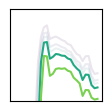

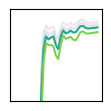

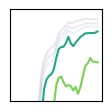

In [56]:
reload(cm.plotting)
# fig, axs = plt.subplots(figsize=(3, 6), nrows=3, ncols=1, layout='constrained', squeeze=True, sharey=True, sharex=True)
figure_name = f"rs_tracer_entrainment_panel_highlight-high"

rs_highlight_ixs = [3, 4]

highlight_alpha = 1
lowlight_alpha = 0.1

for storm_ix, (storm, this_tracer_ds) in enumerate(tracer_totals_dss.items()):
    fig, ax = plt.subplots(figsize=(1, 1), layout='constrained')
    # Rain-sourced
    for ix, tracer in enumerate(blt.RS_TRACERS):
        ax.plot(
            this_tracer_ds["t_minutes"],
            (
                this_tracer_ds[tracer + "_nc"] / this_tracer_ds["air_mass"]
            ).values,
            color=mpl.colormaps[blt.PROGRESSIVE_CMAP](ix / len(blt.RS_TRACERS)),
            alpha=highlight_alpha if ix in rs_highlight_ixs else lowlight_alpha,
            label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[ix]) + " mm/hr")
    if storm_ix == 2:
        blt.label_x_axis(ax)
    ax.set_ylabel("#/kg")
    ax.set_yscale('log')
    ax.set_ylim([1e1, 3e5])
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
    ax.set_ylim(tracer_entrainment_axs[0].get_ylim())

    cm.plotting.fig_multisave(
        fig,
        figure_name + f'_storm-{storm}',
        PRESENTATION_FIGS_DIR,
        no_title_version=False,
        extensions=['.png']
    )

## RS entrainment factors, column

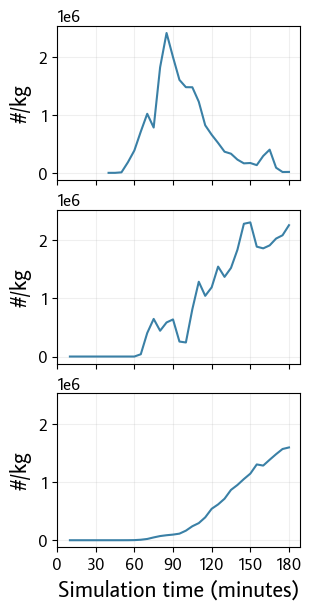

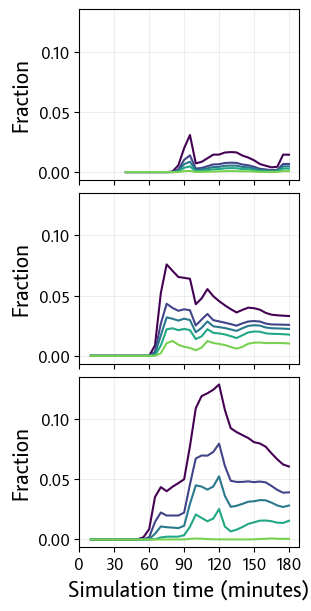

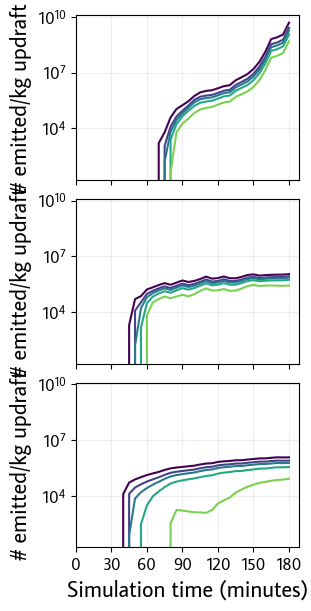

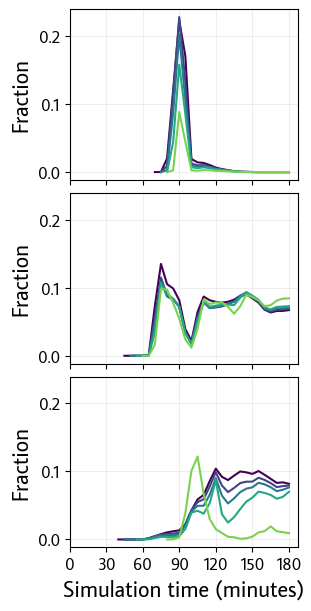

In [34]:
reload(cm.plotting)

figure_data = {}

# Make functions for each row of this figure so that we can easily break them out into their own figures
def rs_factors_fs_entrainment(axs, ax_title_start_ix=0):
    updraft_axs = []
    for storm_ix, (storm, this_tracer_totals_ds) in enumerate(
        tracer_totals_dss.items()
    ):

        ax = axs[storm_ix]

        blt.plot_and_save(
            figure_data,
            f"storm-{storm}_fs_entrainment",
            ax.plot,
            this_tracer_totals_ds["t_minutes"],
            this_tracer_totals_ds["total_fs_tracer_nc"]
            / this_tracer_totals_ds["air_mass"],
            label="Mean FS tracer",
            color=cm.plotting.get_nth_color(0),
        )
        # Add an empty line to make the legend right
        ax.plot([], [], color=cm.plotting.get_nth_color(1), label="Updraft mass")
        # updraft_ax = ax.twinx()
        # updraft_axs.append(updraft_ax)
        # blt.plot_and_save(
        #     figure_data,
        #     f"storm-{storm}_updraft_mass",
        #     updraft_ax.plot,
        #     this_tracer_totals_ds["t_minutes"],
        #     this_tracer_totals_ds["air_mass"],
        #     color=cm.plotting.get_nth_color(1),
        # )
        # updraft_ax.set_yscale("log")

        # ax.set_title(
        #     blt.axes_title(ax_title_start_ix + storm_ix, blt.STORM_LABELS[storm])
        # )

        ax.set_ylabel("#/kg")
        # updraft_ax.set_ylabel("kg")
    blt.label_x_axis(axs[-1])
    

    # Share the y axes of the updraft axes
    # cm.plotting.share_axes(updraft_axs, x=False, y=True)
    # Set the ylim of them
    # for ax in updraft_axs:
    #     ax.set_ylim([1e9, 2e14])

    # axs[1].legend(loc="center", bbox_to_anchor=bbox_to_anchor, ncol=2)
    # cm.plotting.clean_legend(axs[0], loc="upper left")


def rs_factors_rs_fraction(axs, ax_title_start_ix=0):
    for storm_ix, (storm, this_tracer_totals_ds) in enumerate(
        tracer_totals_dss.items()
    ):
        # Second row: RS tracer fraction
        ax = axs[storm_ix]
        for tracer_ix, tracer in enumerate(blt.RS_TRACERS):
            blt.plot_and_save(
                figure_data,
                f"storm-{storm}_rs_fraction",
                ax.plot,
                this_tracer_totals_ds["t_minutes"],
                this_tracer_totals_ds[tracer + "_nc"]
                / this_tracer_totals_ds["total_fs_tracer_nc"],
                label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[tracer_ix]) + " mm/hr",
                color=mpl.colormaps[blt.PROGRESSIVE_CMAP](
                    tracer_ix / len(blt.RS_TRACERS)
                ),
            )
        # ax.set_title(
        #     blt.axes_title(ax_title_start_ix + storm_ix, blt.STORM_LABELS[storm])
        # )
        ax.set_ylabel("Fraction")
    blt.label_x_axis(axs[-1])

        # if storm_ix == 0:
        #     cm.plotting.clean_legend(ax, loc="upper left")
    # axs[1].legend(loc="center", bbox_to_anchor=bbox_to_anchor, ncol=5)


def rs_factors_rain_efficiency(
    axs, ax_title_start_ix=0, storms=tracer_totals_dss.keys()
):
    for storm_ix, storm in enumerate(storms):
        this_tracer_totals_ds = tracer_totals_dss[storm]
        # for storm_ix, (storm, this_tracer_totals_ds) in enumerate(tracer_totals_dss.items()):
        # Third row: Rain production efficiency
        ax = axs[storm_ix]
        for tracer_ix, tracer in enumerate(blt.RS_TRACERS):
            blt.plot_and_save(
                figure_data,
                f"storm-{storm}_rain_efficiency",
                ax.plot,
                this_tracer_totals_ds["t_minutes"],
                this_tracer_totals_ds["ACC" + tracer + "_nc"]
                / this_tracer_totals_ds["air_mass"],
                label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[tracer_ix]) + " mm/hr",
                color=mpl.colormaps[blt.PROGRESSIVE_CMAP](
                    tracer_ix / len(blt.RS_TRACERS)
                ),
            )
            # ax.set_title(
            #     blt.axes_title(ax_title_start_ix + storm_ix, blt.STORM_LABELS[storm])
            # )
        ax.set_ylabel("# emitted/kg updraft")
        ax.set_yscale("log")
    blt.label_x_axis(axs[-1])

        # if storm_ix == 0:
        #     cm.plotting.clean_legend(ax, loc="upper left")
    # axs[1].legend(loc="center", bbox_to_anchor=bbox_to_anchor, ncol=5)


def rs_factors_rs_entrainment_efficiency(axs, ax_title_start_ix=0):
    for storm_ix, (storm, this_tracer_totals_ds) in enumerate(
        tracer_totals_dss.items()
    ):
        ax = axs[storm_ix]
        for tracer_ix, tracer in enumerate(blt.RS_TRACERS):
            blt.plot_and_save(
                figure_data,
                f"storm-{storm}_rs_entrainment_efficiency",
                ax.plot,
                this_tracer_totals_ds["t_minutes"],
                this_tracer_totals_ds[tracer + "_nc"]
                / this_tracer_totals_ds["ACC" + tracer + "_nc"],
                label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[tracer_ix]) + " mm/hr",
                color=mpl.colormaps[blt.PROGRESSIVE_CMAP](
                    tracer_ix / len(blt.RS_TRACERS)
                ),
            )
            # ax.set_title(blt.axes_title(9 + storm_ix, blt.STORM_LABELS[storm]))
        ax.set_ylabel("Fraction")
    blt.label_x_axis(axs[-1])
    # cm.plotting.clean_legend(axs[0], loc="upper left")
    # axs[1].legend(
    #     loc="center",
    #     bbox_to_anchor=(bbox_to_anchor[0], bbox_to_anchor[1] - 0.1),
    #     ncol=5,
    # )


# Create the figure
rs_factors_functions = {
    'fs_entrainment': rs_factors_fs_entrainment,
    'rs_fraction': rs_factors_rs_fraction,
    'rain_efficiency': rs_factors_rain_efficiency,
    'rs_entrainment_efficiency': rs_factors_rs_entrainment_efficiency
}

for figure_name, fn in rs_factors_functions.items():
    fig, axs = plt.subplots(figsize=(3, 6), nrows=3, ncols=1, layout='constrained', squeeze=True, sharex=True, sharey=True)
    fn(axs)
    cm.plotting.fig_multisave(fig, figure_name, PRESENTATION_FIGS_DIR, extensions=['.png'])

# rs_factors_fs_entrainment(axs[0], ax_title_start_ix=0)
# rs_factors_rs_fraction(axs[1], ax_title_start_ix=3)
# rs_factors_rain_efficiency(axs[2], ax_title_start_ix=6)
# rs_factors_rs_entrainment_efficiency(axs[3], ax_title_start_ix=9)


# blt.save_figure_data(figure_data, figure_name)
# cm.plotting.fig_multisave(fig, figure_name, blt.FIGS_DIR)